# PriceWise | Recent product and pricing EDA
**Deliverable:** two reproducible portfolios, their product families, revenue, order units, price tiers, and recent patterns.

**Execution status:** prepared and validated on a separate synthetic test fixture. The actual transaction CSVs were not attached, so this notebook contains no newly computed client results. Run with your `synthesized_FY*.csv` files to generate the findings and figures. Saved outputs from the old EDA are evidence about the old analysis only.

## Business questions
1. Which 30 products have the highest number of transactions during the most recent six calendar months? What families do they belong to?
2. Which five families have the most transactions, and which six products lead each family?
3. How do these portfolios compare on revenue, units, ASP, price tiers, month-to-month movement, and recent data sufficiency?

Stage 1 follows the updated business scope: **Enterprise, shipped invoice records, individual product IDs**. “For everyone” is interpreted as a shared team EDA; change `SEGMENTS` explicitly if the team intended all customer segments. Preserve all repeated records. Neither sparse data nor large transactions are silently deleted. Product selection is by transaction count, not unit volume or revenue.

**Sources reviewed:** `EDA.ipynb`; `Business Scope(3).pdf` (updated Stage 1 rules); `0925_PriceWise_Business_Scope.pptx`; `0925 Client Meeting Notes.pdf` (recency, sparse products, simple explainable methods, psychological pricing). The latest team request defines the two selections. The newer written scope resolves differences with older slides/meeting notes; chatbot, elasticity, optimization, inventory clearance and competitor analysis remain outside this EDA.

## 1. Configuration and definitions
The default window ends at the latest observed shipped-invoice date **for each country**. Set `AS_OF` to a known complete reporting date if available. A data-relative window avoids selecting no products when the synthesized dates differ from today. The exact interval is exported.

A transaction means one input row, including repeated rows, because no confirmed invoice-line key exists. `source_file:source_row` is a reproducible row identifier, not proof that each row is a unique commercial transaction. The CSV filename never replaces the business transaction date.

Use `ship_date` as the event-date proxy; no invoice date exists in the old schema. Missing shipment dates are reported and excluded from time-based analysis, never replaced by order dates or fiscal-file dates.

`revenue` is the provisional monetary field because the old EDA’s cost and margin use it. Audit its difference from `invoice_revenue_country_currency`; confirm the accounting definition before operational pricing. Tax is not added again. US/CA results are separated because the monetary fields’ currency basis is unconfirmed. Country is a partition, not a verified currency label.

In [1]:
from pathlib import Path
from collections import Counter
import json, re, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj): print(obj)
    def Markdown(text): return text

DATA_DIR = Path("/Users/shambhavikhanna/Downloads/Capstone/Data")
FILE_GLOB = "synthesized_FY*.csv"
OUTPUT_DIR = Path("pricewise_eda_results")
SEGMENTS = {"enterprise"}
COUNTRIES = None  # None = all observed countries, each analyzed separately
AS_OF = None  # e.g. "2026-09-30"; never silently substitutes for missing ship_date
REVENUE_COL = "revenue"
CHUNK_SIZE = 250_000
TOP_N = 30
TOP_FAMILIES = 5
PRODUCTS_PER_FAMILY = 6
MIN_30D_TRANSACTIONS = 10  # provisional review threshold, not a client-approved rule
MIN_30D_ACTIVE_DAYS = 5
MAX_RECENCY_DAYS = 14
RUN_CHARTS = True

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
BLUE, TEAL, ORANGE = "#315B96", "#238B83", "#D88632"
REQUIRED = {"segment", "country", "order_status", "document_type", "ship_date",
            "product_id", "product_name", "product_type", "product_family", "order_units", REVENUE_COL}
OPTIONAL = {"return_date", "reason_of_return", "reason_of_cancel", "price_tier",
            "margin", "cost", "invoice_revenue_country_currency", "invoice_quantity", "quarter_fiscal", "customer_id"}
SHIPPED = {"ships", "shipped", "ship"}
RETURNS = {"ret", "return", "returned"}

def safe_div(a, b):
    if isinstance(b, pd.Series):
        return a / b.where(b != 0)
    return a / b if pd.notna(b) and b != 0 else np.nan

def clean_chunk(raw):
    d = raw.copy()
    for c in d.select_dtypes(include=["object", "string"]).columns:
        d[c] = d[c].astype("string").str.strip().replace("", pd.NA)
    for c in ["ship_date", "return_date"]:
        if c in d: d[c] = pd.to_datetime(d[c], errors="coerce").dt.normalize()
    for c in [REVENUE_COL, "order_units", "margin", "cost", "invoice_revenue_country_currency", "invoice_quantity"]:
        if c in d: d[c] = pd.to_numeric(d[c], errors="coerce")
    for c in ["segment", "order_status", "document_type"]:
        d[c] = d[c].str.casefold()
    d["country"] = d["country"].str.upper().fillna("UNKNOWN")
    if "price_tier" not in d: d["price_tier"] = pd.NA
    d["price_tier"] = (d["price_tier"].astype("string").str.replace(r"\s+", "", regex=True)
                        .str.replace("–", "-", regex=False).str.replace("—", "-", regex=False))
    return d

def scope_mask(d):
    m = d["segment"].isin(SEGMENTS)
    if COUNTRIES is not None: m &= d["country"].isin(COUNTRIES)
    return m

def identity_mask(d):
    return d["product_name"].notna() & d["product_type"].notna() & d["product_id"].notna()

def shipped_mask(d):
    return scope_mask(d) & identity_mask(d) & d["order_status"].isin(SHIPPED) & d["document_type"].eq("invoice")

def read_chunks(files):
    for path in files:
        cols = pd.read_csv(path, nrows=0).columns.tolist()
        missing = REQUIRED - set(cols)
        if missing: raise ValueError(f"{path.name}: missing required columns {sorted(missing)}")
        use = [c for c in cols if c in REQUIRED | OPTIONAL]
        # Keep identifiers as strings, including leading zeroes.
        types = {c: "string" for c in use}
        offset = 0
        for raw in pd.read_csv(path, usecols=use, dtype=types, chunksize=CHUNK_SIZE):
            raw["source_file"] = path.name
            raw["source_row"] = np.arange(offset + 1, offset + len(raw) + 1)
            raw["transaction_id"] = path.name + ":" + raw["source_row"].astype(str)
            offset += len(raw)
            yield clean_chunk(raw)

files = sorted(DATA_DIR.glob(FILE_GLOB))
if not files:
    raise FileNotFoundError(f"No {FILE_GLOB} files in {DATA_DIR}. Set DATA_DIR to your actual CSV directory.")
print(f"Input files: {len(files)}. Two chunked passes retain only the recent scoped history.")

Input files: 14. Two chunked passes retain only the recent scoped history.


## 2. Data audit before selection
Pass one counts the exclusions and establishes country-specific dates. Missing product name/type rows are dropped from analysis as required; missing product IDs are additionally excluded because a product-level selection cannot identify them. Missing return/cancellation reasons are not exclusion criteria. Status and document labels are exported so unexpected values can be reviewed.

Fiscal Q1 starts in April. Fiscal year is labeled by its ending year (April 2023 = FY24 Q1). Compare against `quarter_fiscal`; mismatches are a review issue, not automatically corrected raw data.

In [2]:
audit = Counter(); statuses = Counter(); documents = Counter(); country_ends = {}; source_rows = Counter()
for d in read_chunks(files):
    audit["raw_rows"] += len(d)
    source_rows.update(d["source_file"].value_counts().to_dict())
    statuses.update(d["order_status"].fillna("<missing>").value_counts().to_dict())
    documents.update(d["document_type"].fillna("<missing>").value_counts().to_dict())
    audit["missing_product_name_or_type"] += int((d["product_name"].isna() | d["product_type"].isna()).sum())
    s = scope_mask(d)
    audit["scope_rows"] += int(s.sum())
    m = shipped_mask(d)
    audit["eligible_shipped_invoice_rows"] += int(m.sum())
    audit["eligible_missing_ship_date"] += int((m & d["ship_date"].isna()).sum())
    for country, end in d.loc[m].groupby("country")["ship_date"].max().items():
        if pd.notna(end): country_ends[country] = max(country_ends.get(country, end), end)
if not country_ends: raise ValueError("No dated shipped invoices match scope; inspect status/document labels and dates.")
if AS_OF is not None: country_ends = {c: pd.Timestamp(AS_OF).normalize() for c in country_ends}
window_table = pd.DataFrame([
    {"country": c, "as_of": end, "six_month_start": end - pd.DateOffset(months=6) + pd.Timedelta(days=1),
     "history_start": min(end-pd.Timedelta(days=179), end-pd.DateOffset(months=6))}
    for c, end in sorted(country_ends.items())])
audit_table = pd.DataFrame(audit.items(), columns=["check", "rows"])
display(audit_table); display(window_table)
display(pd.DataFrame(statuses.items(), columns=["order_status", "rows"]))
display(pd.DataFrame(documents.items(), columns=["document_type", "rows"]))
audit_table.to_csv(OUTPUT_DIR / "data_audit.csv", index=False)
window_table.to_csv(OUTPUT_DIR / "analysis_windows.csv", index=False)
pd.DataFrame(source_rows.items(), columns=["source_file", "rows"]).to_csv(OUTPUT_DIR / "source_manifest.csv", index=False)

,check,rows
0,raw_rows,11738282
1,missing_product_name_or_type,3210
2,scope_rows,8536801
3,eligible_shipped_invoice_rows,7981192
4,eligible_missing_ship_date,0


,country,as_of,six_month_start,history_start
0,CA,2026-09-01,2026-03-02,2026-03-01
1,US,2026-09-03,2026-03-04,2026-03-03


,order_status,rows
0,ships,11056069
1,cancel,353298
2,ret,281598
3,bck,47317


,document_type,rows
0,invoice,11290381
1,return,281598
2,order,156557
3,warranty service,9746


In [3]:
parts = []; return_parts = []
for d in read_chunks(files):
    ends = d["country"].map(country_ends)
    starts = d["country"].map(dict(zip(window_table.country, window_table.history_start)))
    dates_ok = d["ship_date"].ge(starts) & d["ship_date"].le(ends)
    keep = shipped_mask(d) & dates_ok
    if keep.any(): parts.append(d.loc[keep].copy())
    # Return population is separate; do not double-count non-return statuses just because a reason exists.
    ret_status = d["order_status"].isin(RETURNS) | d["document_type"].eq("return")
    ret_date = d["return_date"] if "return_date" in d else pd.Series(pd.NaT, index=d.index)
    ret = scope_mask(d) & identity_mask(d) & ret_status & ret_date.ge(starts) & ret_date.le(ends)
    if ret.any(): return_parts.append(d.loc[ret].copy())
if not parts: raise ValueError("No eligible observations inside the selected history window.")
ship = pd.concat(parts, ignore_index=True); del parts
returned = pd.concat(return_parts, ignore_index=True) if return_parts else pd.DataFrame()
assert ship["transaction_id"].is_unique
ship["unit_asp"] = safe_div(ship[REVENUE_COL], ship["order_units"])
ship["fiscal_quarter"] = ((ship.ship_date.dt.month - 4) % 12 // 3 + 1).astype(int)
ship["fiscal_year_end"] = ship.ship_date.dt.year + (ship.ship_date.dt.month >= 4).astype(int)
ship["derived_fiscal_period"] = "FY" + (ship.fiscal_year_end % 100).astype(str).str.zfill(2) + "Q" + ship.fiscal_quarter.astype(str)
ship["month"] = ship.ship_date.dt.to_period("M").dt.to_timestamp()
ship["is_quarter_end_month"] = ship.ship_date.dt.month.isin([3, 6, 9, 12])
ship["metric_valid"] = ship[REVENUE_COL].notna() & ship.order_units.notna()
ship["price_valid"] = ship.metric_valid & ship.order_units.gt(0) & ship[REVENUE_COL].gt(0)
checks = {
 "retained_history_rows": len(ship),
 "missing_revenue_or_units": int((~ship.metric_valid).sum()),
 "nonpositive_units": int(ship.order_units.le(0).sum()),
 "nonpositive_revenue": int(ship[REVENUE_COL].le(0).sum()),
 "missing_family": int(ship.product_family.isna().sum()),
 "missing_price_tier": int(ship.price_tier.isna().sum()),
}
if "margin" in ship and "cost" in ship:
    known = ship[["margin", "cost", REVENUE_COL]].notna().all(axis=1)
    checks["margin_identity_mismatch"] = int((known & (ship.margin - (ship[REVENUE_COL] - ship.cost)).abs().gt(.02)).sum())
if "invoice_revenue_country_currency" in ship:
    known = ship[[REVENUE_COL, "invoice_revenue_country_currency"]].notna().all(axis=1)
    checks["revenue_fields_differ"] = int((known & (ship[REVENUE_COL]-ship.invoice_revenue_country_currency).abs().gt(.02)).sum())
if "quarter_fiscal" in ship:
    checks["supplied_vs_derived_fiscal_mismatch"] = int((ship.quarter_fiscal.notna() & ship.quarter_fiscal.ne(ship.derived_fiscal_period)).sum())
quality = pd.DataFrame(checks.items(), columns=["check", "rows"])
display(quality)
quality.to_csv(OUTPUT_DIR / "recent_history_quality.csv", index=False)
# Missing revenue/units never become fabricated zeroes. Keep a quality count beside each aggregate.
def sums(g):
    return g.sum(min_count=1)

,check,rows
0,retained_history_rows,1067140
1,missing_revenue_or_units,0
2,nonpositive_units,0
3,nonpositive_revenue,499412
4,missing_family,363
5,missing_price_tier,0
6,margin_identity_mismatch,1974
7,revenue_fields_differ,79285
8,supplied_vs_derived_fiscal_mismatch,0


## 3. Selection logic: two distinct portfolios
For each country, restrict to the exact six-month interval and count eligible rows. Resolve each product ID’s family to the family with the most recent-window transactions; break ties alphabetically and flag conflicting assignments. Missing family remains `Unknown family` and does not enter the top-five family ranking. This assigns each product to one family, avoiding repeated selection of the same ID across families.

Rank products and families by transaction count, then revenue, then ID/family name for reproducible ties. Family portfolio: rank all resolved families first, then take up to six products per selected family. Report shortfalls rather than filling them from unrelated families. Rank at most 30 in the overall portfolio. **No sufficiency filter changes the requested transaction-based selection**; readiness flags are added afterward.

Rows with negative or missing monetary values still count as transactions. Financial totals retain signed entries and missing-value counts. Positive-price comparisons use a separately identified subset.

In [4]:
def summarize_products(d):
    g = d.groupby("product_id", sort=False)
    p = g.agg(transactions=("transaction_id", "size"), revenue=(REVENUE_COL, sums),
              units=("order_units", sums), active_days=("ship_date", "nunique"),
              first_ship=("ship_date", "min"), last_ship=("ship_date", "max"),
              invalid_metric_rows=("metric_valid", lambda x: int((~x).sum())))
    for c in ["margin", "cost"]:
        if c in d: p[c] = g[c].agg(sums)
    p["asp"] = safe_div(p.revenue, p.units)
    if "margin" in p: p["margin_rate"] = safe_div(p.margin, p.revenue)
    for c in ["product_name", "product_type", "product_family"]:
        counts = d.assign(**{c: d[c].fillna("Unknown family" if c == "product_family" else "Unknown")}).groupby(["product_id", c]).size().rename("n").reset_index()
        best = counts.sort_values(["product_id", "n", c], ascending=[True, False, True]).drop_duplicates("product_id").set_index("product_id")[c]
        p[c] = best
        p[c + "_variants"] = counts.groupby("product_id").size()
    return p.reset_index()

def build_portfolios(d, end):
    start = end - pd.DateOffset(months=6) + pd.Timedelta(days=1)
    recent = d.loc[d.ship_date.between(start, end)].copy()
    p = summarize_products(recent)
    p = p.sort_values(["transactions", "revenue", "product_id"], ascending=[False, False, True], na_position="last").reset_index(drop=True)
    p["overall_rank"] = np.arange(1, len(p)+1)
    p["transaction_share"] = p.transactions / len(recent)
    fam = p.loc[p.product_family.ne("Unknown family")].groupby("product_family").agg(
        transactions=("transactions", "sum"), revenue=("revenue", sums), units=("units", sums), available_products=("product_id", "nunique"))
    fam = fam.reset_index().sort_values(["transactions", "revenue", "product_family"], ascending=[False, False, True]).head(TOP_FAMILIES)
    fam["family_rank"] = np.arange(1, len(fam)+1)
    fam["selected_products"] = fam.available_products.clip(upper=PRODUCTS_PER_FAMILY)
    fam["shortfall"] = PRODUCTS_PER_FAMILY - fam.selected_products
    family_products = p.merge(fam[["product_family", "family_rank"]], on="product_family", how="inner")
    family_products = family_products.sort_values(["family_rank", "transactions", "revenue", "product_id"], ascending=[True, False, False, True])
    family_products["within_family_rank"] = family_products.groupby("product_family").cumcount()+1
    family_products = family_products.loc[family_products.within_family_rank.le(PRODUCTS_PER_FAMILY)].copy()
    top = p.head(TOP_N).copy()
    ids = sorted(set(top.product_id) | set(family_products.product_id))
    membership = p.loc[p.product_id.isin(ids)].copy()
    membership["in_overall_top30"] = membership.product_id.isin(top.product_id)
    membership["in_family_top6"] = membership.product_id.isin(family_products.product_id)
    return recent, p, top, fam, family_products, membership

analyses = {}
for country, end in country_ends.items():
    d = ship.loc[ship.country.eq(country)].copy()
    if d.empty: continue
    recent, p, top, fam, fp, membership = build_portfolios(d, end)
    if recent.empty: continue
    analyses[country] = dict(history=d, recent=recent, products=p, top=top, families=fam, family_products=fp, membership=membership, end=end)
    print(f"{country}: {len(recent):,} transactions; overall portfolio {len(top)} products; family portfolio {len(fp)} products; union {len(membership)}.")
    display(top[["overall_rank", "product_id", "product_name", "product_family", "product_type", "transactions", "revenue", "units", "asp"]])
    display(fam)
    display(fp[["family_rank", "product_family", "within_family_rank", "product_id", "product_name", "transactions", "revenue", "units", "asp"]])

CA: 164,802 transactions; overall portfolio 30 products; family portfolio 26 products; union 42.


,overall_rank,product_id,product_name,product_family,product_type,transactions,revenue,units,asp
0,1,CMEG685,LIBERTY INTEGRAL JUNCTION (FKA),Product Family Fusion Echo,Shipping,74755,0.0,74755.0,0.0
1,2,KEZB478,ELEMENT SOLSTICE MOMENTUM (ITK),Product Family Fusion Echo,Shipping,5184,0.0,5184.0,0.0
2,3,4Q01B61187,SUN GJJ_PA 171D PUP-Q ARC ZTOUZUR-IO,Product Family Romeo Iris,Options,1953,54480.58,3123.0,17.44495
3,4,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,Product Family Romeo Iris,Options,1789,500513.33,3602.0,138.954284
4,5,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,Product Family Romeo Iris,Services,1348,4319.67,2439.0,1.771082
5,6,5VE7H16777,FRONTIER 0S FOXTROT CHARLIE STAR,Product Family Romeo Iris,Services,1269,70473.55,1269.0,55.534712
6,7,18FS8100BR,SO YWB-E ECHO 934D CHARLIE,Product Family Romeo Iris,Options,1080,289980.21,2102.0,137.954429
7,8,9TE3M17113,MOMENTUM 0J FORTUNE MONARCH IRIS,Product Family Romeo Iris,Services,995,128766.57,995.0,129.413638
8,9,1CL5K06249,INTEGRAL 7R PACIFIC PIONEER GATE,Product Family Romeo Iris,Services,922,3199.38,1631.0,1.961606
9,10,8WR6F40191,MOMENTUM 1L CYPRESS INSIGHT LIMA,Product Family Romeo Iris,Services,817,2631.95,1450.0,1.815138


,product_family,transactions,revenue,units,available_products,family_rank,selected_products,shortfall
2,Product Family Fusion Echo,79939,0.0,79939.0,2,1,2,4
6,Product Family Romeo Iris,49028,6193922.26,79637.0,816,2,6,0
4,Product Family Knight Thrive,11803,20409266.26,20024.0,119,3,6,0
1,Product Family Frame Road,8269,21213289.57,12183.0,88,4,6,0
8,Product Family Solar Peak,6432,21034002.38,9325.0,104,5,6,0


,family_rank,product_family,within_family_rank,product_id,product_name,transactions,revenue,units,asp
0,1,Product Family Fusion Echo,1,CMEG685,LIBERTY INTEGRAL JUNCTION (FKA),74755,0.0,74755.0,0.0
1,1,Product Family Fusion Echo,2,KEZB478,ELEMENT SOLSTICE MOMENTUM (ITK),5184,0.0,5184.0,0.0
2,2,Product Family Romeo Iris,1,4Q01B61187,SUN GJJ_PA 171D PUP-Q ARC ZTOUZUR-IO,1953,54480.58,3123.0,17.44495
3,2,Product Family Romeo Iris,2,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,1789,500513.33,3602.0,138.954284
4,2,Product Family Romeo Iris,3,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,1348,4319.67,2439.0,1.771082
5,2,Product Family Romeo Iris,4,5VE7H16777,FRONTIER 0S FOXTROT CHARLIE STAR,1269,70473.55,1269.0,55.534712
6,2,Product Family Romeo Iris,5,18FS8100BR,SO YWB-E ECHO 934D CHARLIE,1080,289980.21,2102.0,137.954429
7,2,Product Family Romeo Iris,6,9TE3M17113,MOMENTUM 0J FORTUNE MONARCH IRIS,995,128766.57,995.0,129.413638
11,3,Product Family Knight Thrive,1,95SS294NWP,U04 W9,736,1419759.08,1368.0,1037.835585
16,3,Product Family Knight Thrive,2,17D4481BEM,C75 C9,657,1121043.95,1212.0,924.953754


US: 892,300 transactions; overall portfolio 30 products; family portfolio 29 products; union 44.


,overall_rank,product_id,product_name,product_family,product_type,transactions,revenue,units,asp
0,1,CMEG685,LIBERTY INTEGRAL JUNCTION (FKA),Product Family Fusion Echo,Shipping,282270,0.0,282270.0,0.0
1,2,QLVX570,MONARCH FRONTIER CATALYST (VFG),Product Family Fusion Echo,Shipping,127018,160122.9,127018.0,1.260632
2,3,1OK4L65577,MONARCH 1-OJLA 84X ZULU CATALYST,Product Family Romeo Iris,Services,9878,276892.97,28162.0,9.832149
3,4,OMXO798,HORIZON NOVEMBER NOVEMBER (PQH),Product Family Fusion Echo,Shipping,8376,411219.94,8376.0,49.095026
4,5,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,Product Family Romeo Iris,Options,7956,2098537.14,15891.0,132.058218
5,6,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,Product Family Romeo Iris,Services,6666,26312.3,13772.0,1.910565
6,7,18FS8100BR,SO YWB-E ECHO 934D CHARLIE,Product Family Romeo Iris,Options,6058,1747351.1,12178.0,143.484242
7,8,5VE7H16777,FRONTIER 0S FOXTROT CHARLIE STAR,Product Family Romeo Iris,Services,5724,320594.09,5724.0,56.008751
8,9,37T3KSB9JI,90U0126HPY SIGNAL WAY,Product Family Frame Road,Notebook,5504,19972978.73,8360.0,2389.112288
9,10,2GC7I50836,CHARLIE RM274QPNRK,Product Family Romeo Iris,Options,5063,677409.7,5288.0,128.103196


,product_family,transactions,revenue,units,available_products,family_rank,selected_products,shortfall
2,Product Family Fusion Echo,419411,571612.75,419411.0,5,1,5,1
6,Product Family Romeo Iris,264252,53659197.98,479268.0,973,2,6,0
1,Product Family Frame Road,63566,210979583.33,117339.0,103,3,6,0
4,Product Family Knight Thrive,53257,107074814.66,107718.0,129,4,6,0
8,Product Family Solar Peak,42788,176201548.9,72074.0,136,5,6,0


,family_rank,product_family,within_family_rank,product_id,product_name,transactions,revenue,units,asp
0,1,Product Family Fusion Echo,1,CMEG685,LIBERTY INTEGRAL JUNCTION (FKA),282270,0.0,282270.0,0.0
1,1,Product Family Fusion Echo,2,QLVX570,MONARCH FRONTIER CATALYST (VFG),127018,160122.9,127018.0,1.260632
3,1,Product Family Fusion Echo,3,OMXO798,HORIZON NOVEMBER NOVEMBER (PQH),8376,411219.94,8376.0,49.095026
62,1,Product Family Fusion Echo,4,KEZB478,ELEMENT SOLSTICE MOMENTUM (ITK),1736,0.0,1736.0,0.0
984,1,Product Family Fusion Echo,5,RYOT483,CENTURY NOVEMBER SENTINEL (IAU),11,269.91,11.0,24.537273
2,2,Product Family Romeo Iris,1,1OK4L65577,MONARCH 1-OJLA 84X ZULU CATALYST,9878,276892.97,28162.0,9.832149
4,2,Product Family Romeo Iris,2,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,7956,2098537.14,15891.0,132.058218
5,2,Product Family Romeo Iris,3,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,6666,26312.3,13772.0,1.910565
6,2,Product Family Romeo Iris,4,18FS8100BR,SO YWB-E ECHO 934D CHARLIE,6058,1747351.1,12178.0,143.484242
7,2,Product Family Romeo Iris,5,5VE7H16777,FRONTIER 0S FOXTROT CHARLIE STAR,5724,320594.09,5724.0,56.008751


## 4. Revenue, units, pricing and operational readiness
ASP is **sum of revenue / sum of order units**, never the mean of row ASPs. Compute current 30 days, immediately preceding 30 days, current 90 days, and previous non-overlapping 90 days. Missing values remain visible. A zero earlier denominator produces an undefined growth rate, not infinite growth or an invented percentage.

Recent readiness is a provisional review flag: at least 10 transactions on five active days in 30 days, last shipment within 14 days, positive aggregate revenue and units, no missing revenue/units in that window, and unambiguous family assignment. The rule responds to the client’s sparse/stale product concern; it does not validate demand response or authorize price changes.

Calendar zeroes in product-day summaries mean **no recorded eligible transaction**, not proven no demand. A day with an invalid measurement remains missing for that metric. Feed completeness is not known from these files.

In [5]:
def window_metrics(d, lo, hi, prefix, ids):
    x = d.loc[d.ship_date.between(lo, hi) & d.product_id.isin(ids)]
    base = pd.DataFrame(index=pd.Index(ids, name="product_id"))
    if not x.empty:
        z = x.groupby("product_id").agg(revenue=(REVENUE_COL, sums), units=("order_units", sums),
                    transactions=("transaction_id", "size"), active_days=("ship_date", "nunique"),
                    invalid_metric_rows=("metric_valid", lambda v: int((~v).sum())))
        if "margin" in x: z["margin"] = x.groupby("product_id").margin.agg(sums)
        base = base.join(z)
    for c in ["revenue", "units", "transactions", "active_days", "invalid_metric_rows"]:
        if c not in base: base[c] = np.nan
    # Count absence is zero; money/units is zero only for products with no rows in this window.
    absent = base.transactions.isna()
    base.loc[absent, ["revenue", "units", "transactions", "active_days", "invalid_metric_rows"]] = 0
    base["asp"] = safe_div(base.revenue, base.units)
    if "margin" in base: base["margin_rate"] = safe_div(base.margin, base.revenue)
    return base.add_prefix(prefix + "_").reset_index()

for c, a in analyses.items():
    end, d, member = a["end"], a["history"], a["membership"].copy()
    ids = member.product_id.tolist()
    for prefix, lo, hi in [
        ("current30", end-pd.Timedelta(days=29), end),
        ("previous30", end-pd.Timedelta(days=59), end-pd.Timedelta(days=30)),
        ("current90", end-pd.Timedelta(days=89), end),
        ("previous90", end-pd.Timedelta(days=179), end-pd.Timedelta(days=90))]:
        member = member.merge(window_metrics(d, lo, hi, prefix, ids), on="product_id", how="left", validate="one_to_one")
    member["days_since_last_ship"] = (end - member.last_ship).dt.days
    member["unit_change_30d"] = member.current30_units - member.previous30_units
    member["unit_growth_30d"] = safe_div(member.unit_change_30d, member.previous30_units.where(member.previous30_units.gt(0)))
    member["asp_change_30d"] = safe_div(member.current30_asp - member.previous30_asp, member.previous30_asp.where(member.previous30_asp.gt(0)))
    member["recent_review_ready"] = (member.current30_transactions.ge(MIN_30D_TRANSACTIONS) &
        member.current30_active_days.ge(MIN_30D_ACTIVE_DAYS) & member.days_since_last_ship.le(MAX_RECENCY_DAYS) &
        member.current30_revenue.gt(0) & member.current30_units.gt(0) &
        member.current30_invalid_metric_rows.eq(0) & member.product_family_variants.eq(1) & member.product_family.ne("Unknown family"))
    def reasons(r):
        v = []
        if r.current30_transactions < MIN_30D_TRANSACTIONS: v.append("few recent transactions")
        if r.current30_active_days < MIN_30D_ACTIVE_DAYS: v.append("few active sales days")
        if r.days_since_last_ship > MAX_RECENCY_DAYS: v.append("stale sales")
        if not (r.current30_revenue > 0 and r.current30_units > 0): v.append("invalid recent price basis")
        if r.current30_invalid_metric_rows > 0: v.append("missing revenue/units")
        if r.product_family_variants != 1 or r.product_family == "Unknown family": v.append("family needs review")
        return "; ".join(v) or "passes provisional recent-data checks"
    member["readiness_reason"] = member.apply(reasons, axis=1)
    # Family ASP is context only; explicitly quantify how far it is from the product.
    h90 = d.loc[d.ship_date.between(end-pd.Timedelta(days=89), end)]
    resolved = h90.merge(a["products"][["product_id", "product_family"]].rename(columns={"product_family":"resolved_family"}), on="product_id", how="left")
    fm = resolved.groupby("resolved_family").agg(revenue=(REVENUE_COL, sums), units=("order_units", sums))
    fm["family90_asp"] = safe_div(fm.revenue, fm.units)
    member = member.merge(fm[["family90_asp"]], left_on="product_family", right_index=True, how="left")
    member["family_vs_product_asp_ratio"] = safe_div(member.family90_asp, member.current30_asp.where(member.current30_asp.gt(0)))
    member["illustrative_baseline_50_30_20"] = .5*member.current30_asp + .3*member.family90_asp + .2*member.previous90_asp
    member["baseline_component_missing"] = member[["current30_asp", "family90_asp", "previous90_asp"]].isna().any(axis=1)
    # Observed inactivity gaps between shipment days; not evidence of missing demand.
    unique_days = d.loc[d.product_id.isin(ids)].groupby("product_id").ship_date.apply(lambda v: sorted(v.unique()))
    member["max_observed_gap_days"] = member.product_id.map(unique_days.map(lambda dates: max([(pd.Timestamp(b)-pd.Timestamp(a)).days for a,b in zip(dates,dates[1:])], default=0)))
    member["family_price_context_needs_review"] = member.family_vs_product_asp_ratio.lt(.5) | member.family_vs_product_asp_ratio.gt(2)
    a["detail"] = member
    display(member[["product_id", "product_family", "current30_transactions", "current30_units", "previous30_units", "unit_growth_30d", "current30_asp", "days_since_last_ship", "recent_review_ready", "readiness_reason"]])

,product_id,product_family,current30_transactions,current30_units,previous30_units,unit_growth_30d,current30_asp,days_since_last_ship,recent_review_ready,readiness_reason
0,CMEG685,Product Family Fusion Echo,13911.0,13911.0,9564.0,0.454517,0.0,0,False,invalid recent price basis
1,KEZB478,Product Family Fusion Echo,1169.0,1169.0,1159.0,0.008628,0.0,3,False,invalid recent price basis
2,4Q01B61187,Product Family Romeo Iris,360.0,501.0,441.0,0.136054,17.826307,4,True,passes provisional recent-data checks
3,27WH3132DN,Product Family Romeo Iris,0.0,0.0,0.0,<NA>,<NA>,91,False,few recent transactions; few active sales days...
4,7LL8J24163,Product Family Romeo Iris,272.0,458.0,248.0,0.846774,1.317358,3,True,passes provisional recent-data checks
5,5VE7H16777,Product Family Romeo Iris,334.0,334.0,106.0,2.150943,72.792425,3,True,passes provisional recent-data checks
6,18FS8100BR,Product Family Romeo Iris,58.0,120.0,90.0,0.333333,122.657167,13,True,passes provisional recent-data checks
7,9TE3M17113,Product Family Romeo Iris,91.0,91.0,171.0,-0.467836,149.524505,3,True,passes provisional recent-data checks
8,1CL5K06249,Product Family Romeo Iris,144.0,217.0,232.0,-0.064655,2.430138,3,True,passes provisional recent-data checks
9,8WR6F40191,Product Family Romeo Iris,210.0,375.0,274.0,0.368613,1.962613,3,True,passes provisional recent-data checks


,product_id,product_family,current30_transactions,current30_units,previous30_units,unit_growth_30d,current30_asp,days_since_last_ship,recent_review_ready,readiness_reason
0,CMEG685,Product Family Fusion Echo,49304.0,49304.0,46430.0,0.0619,0.0,4,False,invalid recent price basis
1,QLVX570,Product Family Fusion Echo,21405.0,21405.0,20365.0,0.051068,1.56782,1,True,passes provisional recent-data checks
2,1OK4L65577,Product Family Romeo Iris,1362.0,3691.0,4498.0,-0.179413,9.810826,4,True,passes provisional recent-data checks
3,OMXO798,Product Family Fusion Echo,1454.0,1454.0,1099.0,0.323021,49.938446,5,True,passes provisional recent-data checks
4,27WH3132DN,Product Family Romeo Iris,0.0,0.0,0.0,<NA>,<NA>,64,False,few recent transactions; few active sales days...
5,7LL8J24163,Product Family Romeo Iris,933.0,1990.0,1355.0,0.468635,2.576447,5,True,passes provisional recent-data checks
6,18FS8100BR,Product Family Romeo Iris,28.0,53.0,730.0,-0.927397,131.106792,22,False,stale sales
7,5VE7H16777,Product Family Romeo Iris,1251.0,1251.0,620.0,1.017742,56.088177,5,True,passes provisional recent-data checks
8,37T3KSB9JI,Product Family Frame Road,1282.0,1766.0,3082.0,-0.426995,2462.21487,6,True,passes provisional recent-data checks
9,2GC7I50836,Product Family Romeo Iris,912.0,978.0,773.0,0.265201,118.074581,5,True,passes provisional recent-data checks


## 5. Monthly patterns, tier consistency and return-related signals
Show transaction counts, units, revenue and weighted ASP separately. Partial first/last months are labeled; raw totals in a partial month should not be compared directly with a full month. Report recorded transactions per calendar day as an exposure-adjusted view, with feed completeness still unverified.

Normalize whitespace in price tiers so `$700  -  $999` and `$700 - $999` become one tier. Compare positive realized per-row ASP against the tier. Tier upper integers are treated as inclusive of cents (e.g. $299.99 in $0–$299); confirm this convention with stakeholders. Multiple tiers per product and family mixes can explain wide price variation. A family ASP is not a like-for-like price substitute.

Returns are counted using return status/document plus `return_date`; reason alone does not establish a return. Return units use absolute values because the source may sign them negative. Same-window returned units / shipped units is a **flow ratio**, not a linked shipped-cohort return probability. Delays can make it exceed 100%. Missing return dates prevent inclusion; no reasons are filled or deleted.

In [6]:
def tier_bounds(value):
    if pd.isna(value): return np.nan, np.nan
    text = str(value).replace("$", "").replace(",", "")
    if re.fullmatch(r"\d+(?:\.\d+)?\+", text): return float(text[:-1]), np.inf
    m = re.fullmatch(r"(\d+(?:\.\d+)?)-(\d+(?:\.\d+)?)", text)
    if m: return float(m.group(1)), float(m.group(2)) + 1
    return np.nan, np.nan

for c, a in analyses.items():
    x = a["recent"].loc[a["recent"].product_id.isin(a["membership"].product_id)].copy()
    monthly = x.groupby(["product_id", "month"]).agg(transactions=("transaction_id", "size"), revenue=(REVENUE_COL, sums), units=("order_units", sums))
    start = a["end"]-pd.DateOffset(months=6)+pd.Timedelta(days=1)
    periods = pd.date_range(start.to_period("M").to_timestamp(), a["end"].to_period("M").to_timestamp(), freq="MS")
    full = pd.MultiIndex.from_product([a["membership"].product_id, periods], names=["product_id", "month"])
    monthly = monthly.reindex(full)
    absent = monthly.transactions.isna()
    monthly.loc[absent, ["transactions", "revenue", "units"]] = 0
    monthly = monthly.reset_index()
    start = a["end"]-pd.DateOffset(months=6)+pd.Timedelta(days=1)
    monthly["window_days"] = monthly.month.map(lambda t: (min(t+pd.offsets.MonthEnd(0), a["end"])-max(t,start)).days+1)
    monthly["partial_month"] = monthly.window_days.lt(monthly.month.dt.days_in_month)
    monthly["transactions_per_calendar_day"] = monthly.transactions / monthly.window_days
    monthly["asp"] = safe_div(monthly.revenue, monthly.units)
    a["monthly"] = monthly
    tier = x.groupby(["product_id", "price_tier"], dropna=False).agg(transactions=("transaction_id", "size"), revenue=(REVENUE_COL, sums), units=("order_units", sums)).reset_index()
    tier["transaction_share_within_product"] = tier.transactions / tier.groupby("product_id").transactions.transform("sum")
    a["tiers"] = tier
    bounds = x.price_tier.map(tier_bounds)
    x["tier_low"] = [v[0] for v in bounds]; x["tier_upper_exclusive"] = [v[1] for v in bounds]
    x["tier_comparable"] = x.price_valid & x.tier_low.notna()
    x["tier_mismatch"] = x.tier_comparable & (~x.unit_asp.ge(x.tier_low) | ~x.unit_asp.lt(x.tier_upper_exclusive))
    cents = (x.unit_asp*100).round()
    x["ends_99"] = x.price_valid & cents.mod(100).eq(99)
    x["very_large_order"] = x.order_units.gt(x.loc[x.order_units.gt(0), "order_units"].quantile(.99))
    flags = x.groupby("product_id").agg(tier_comparable_rows=("tier_comparable","sum"), tier_mismatches=("tier_mismatch","sum"),
            positive_price_rows=("price_valid","sum"), observed_99_endings=("ends_99","sum"), large_order_rows=("very_large_order","sum"))
    flags["tier_mismatch_rate"] = safe_div(flags.tier_mismatches, flags.tier_comparable_rows)
    flags["observed_99_ending_rate"] = safe_div(flags.observed_99_endings, flags.positive_price_rows)
    flags["tier_variants"] = x.groupby("product_id").price_tier.nunique()
    a["pricing_flags"] = flags.reset_index()
    coverage = []
    for n in [20,25,30]:
        selected = a["products"].head(n)
        coverage.append({"requested_products":n,"available_selected":len(selected),
             "transaction_coverage":selected.transactions.sum()/len(a["recent"]),
             "revenue_coverage":safe_div(selected.revenue.sum(min_count=1),a["recent"][REVENUE_COL].sum(min_count=1)),
             "units_coverage":safe_div(selected.units.sum(min_count=1),a["recent"].order_units.sum(min_count=1))})
    a["portfolio_coverage"] = pd.DataFrame(coverage)
    a["product_type_mix"] = x.groupby("product_type",dropna=False).agg(transactions=("transaction_id","size"),revenue=(REVENUE_COL,sums),units=("order_units",sums)).reset_index()
    display(a["portfolio_coverage"]); display(a["product_type_mix"])
    a["outlier_examples"] = x.loc[x.very_large_order | x.tier_mismatch | ~x.metric_valid | x.order_units.le(0) | x[REVENUE_COL].le(0),
        ["transaction_id", "product_id", "ship_date", "order_units", REVENUE_COL, "unit_asp", "price_tier", "tier_mismatch"]].sort_values("order_units", ascending=False).head(100)
    if not returned.empty:
        r = returned.loc[returned.country.eq(c) & returned.return_date.between(start,a["end"])]
        ret = r.groupby("product_id").agg(return_records=("transaction_id","size"), returned_units=("order_units", lambda q: q.abs().sum(min_count=1)))
        ret = a["membership"][["product_id", "units"]].merge(ret, left_on="product_id", right_index=True, how="left")
        absent = ret.return_records.isna(); ret.loc[absent,["return_records","returned_units"]] = 0
        ret["returned_to_shipped_unit_flow_ratio"] = safe_div(ret.returned_units,ret.units.where(ret.units.gt(0)))
        a["returns"] = ret
    else: a["returns"] = pd.DataFrame(columns=["product_id", "return_records", "returned_units", "returned_to_shipped_unit_flow_ratio"])
    display(a["pricing_flags"])

,requested_products,available_selected,transaction_coverage,revenue_coverage,units_coverage
0,20,20,0.587499,0.065479,0.488135
1,25,25,0.603567,0.088964,0.511093
2,30,30,0.619009,0.110665,0.533070


,product_type,transactions,revenue,units
0,Notebook,6021,12255730.12,9630.0
1,Options,8920,1418003.26,15182.0
2,Services,8594,377335.37,13097.0
3,Shipping,79939,0.0,79939.0
4,Visuals,1041,404938.82,3412.0
5,Workstations,1999,5650158.17,3506.0


,product_id,tier_comparable_rows,tier_mismatches,positive_price_rows,observed_99_endings,large_order_rows,tier_mismatch_rate,observed_99_ending_rate,tier_variants
0,01S94612NN,327,0,327,4,5,0.0,0.012232,5
1,02XJSFY3QN,479,0,479,3,2,0.0,0.006263,7
2,03DF114WYO,431,0,431,4,1,0.0,0.009281,7
3,07SFBS78RD,477,0,477,3,3,0.0,0.006289,1
4,0G77A12974,641,0,641,4,34,0.0,0.00624,1
5,10TBMCG2LC,271,0,271,2,4,0.0,0.00738,7
6,14XOTJR8EF,396,0,396,6,7,0.0,0.015152,8
7,16CHOUW4TD,572,0,572,6,2,0.0,0.01049,7
8,16T0MJI6WJ,328,0,328,7,13,0.0,0.021341,8
9,17D4481BEM,657,0,657,5,10,0.0,0.00761,5


,requested_products,available_selected,transaction_coverage,revenue_coverage,units_coverage
0,20,20,0.569853,0.084019,0.441056
1,25,25,0.589241,0.113163,0.465187
2,30,30,0.605626,0.140181,0.486528


,product_type,transactions,revenue,units
0,Notebook,37216,101926726.51,68353.0
1,Options,48574,12616857.6,84490.0
2,Services,50278,2363435.83,92063.0
3,Shipping,419411,571612.75,419411.0
4,Workstations,10463,40622247.68,19357.0


,product_id,tier_comparable_rows,tier_mismatches,positive_price_rows,observed_99_endings,large_order_rows,tier_mismatch_rate,observed_99_ending_rate,tier_variants
0,01S94612NN,2198,0,2198,12,34,0.0,0.00546,8
1,02CAMJV4NR,1233,0,1233,20,30,0.0,0.016221,7
2,02XJSFY3QN,2323,0,2323,10,51,0.0,0.004305,9
3,03DF114WYO,2288,0,2288,33,43,0.0,0.014423,7
4,05BC2790OV,2282,0,2282,23,40,0.0,0.010079,6
5,05DXFDL9QE,1332,0,1332,16,18,0.0,0.012012,6
6,0G77A12974,2971,0,2971,1065,126,0.0,0.358465,1
7,14XOTJR8EF,2297,0,2297,26,67,0.0,0.011319,9
8,16CHOUW4TD,3134,0,3134,20,64,0.0,0.006382,8
9,17D4481BEM,5025,0,5025,39,24,0.0,0.007761,7


## 6. Explanatory figures
Figures answer the selection and pricing questions directly. Product IDs appear in dense plots; full names and families are in the exported tables. Colors distinguish the two portfolio memberships consistently. Small multiples avoid placing 30–60 trajectories in one crowded legend.

The transaction-frequency heatmap includes recorded zeroes. The trend panels pair units with ASP; simultaneous movement is descriptive and can reflect contracts, discounts, customer mix or product lifecycle. It is not a causal elasticity estimate. No price change is recommended from correlation alone.

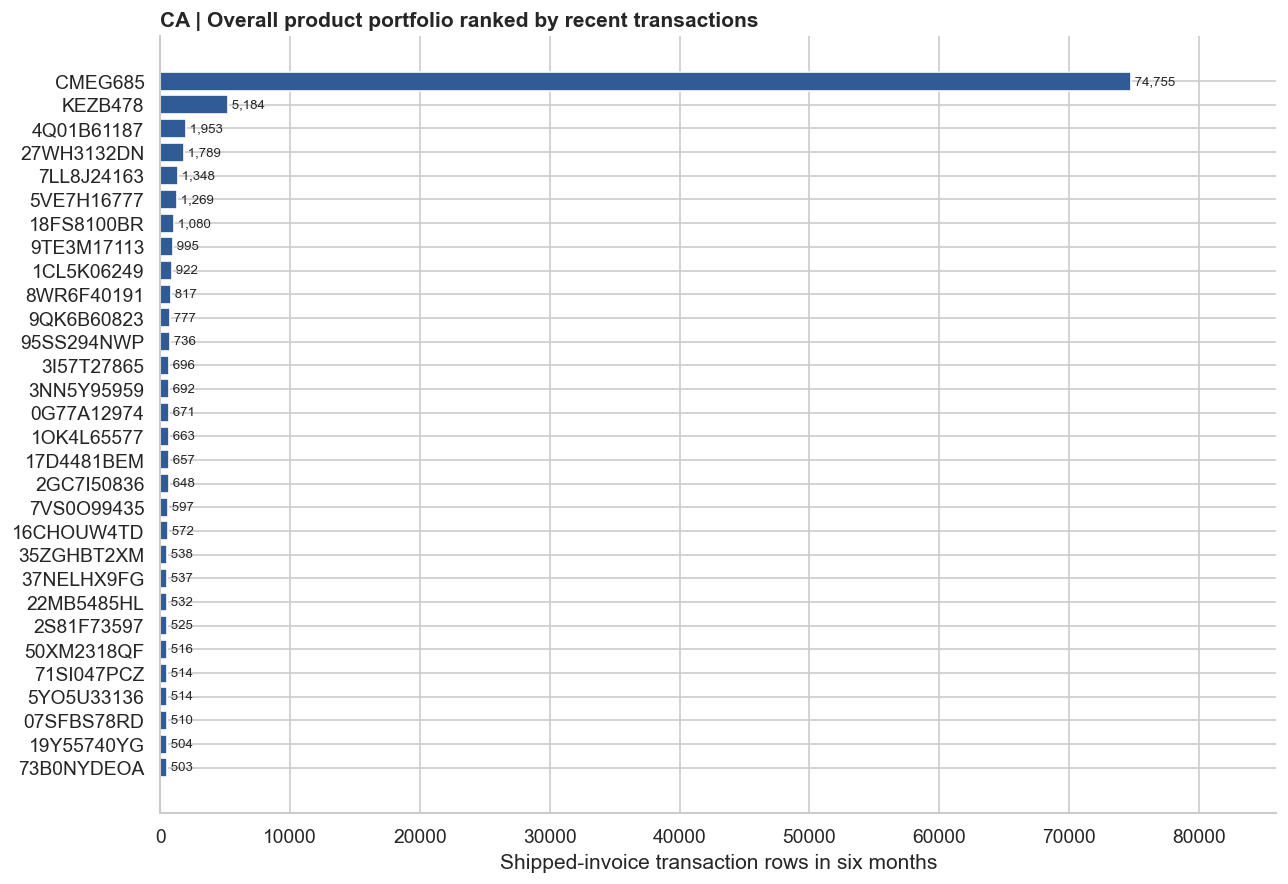

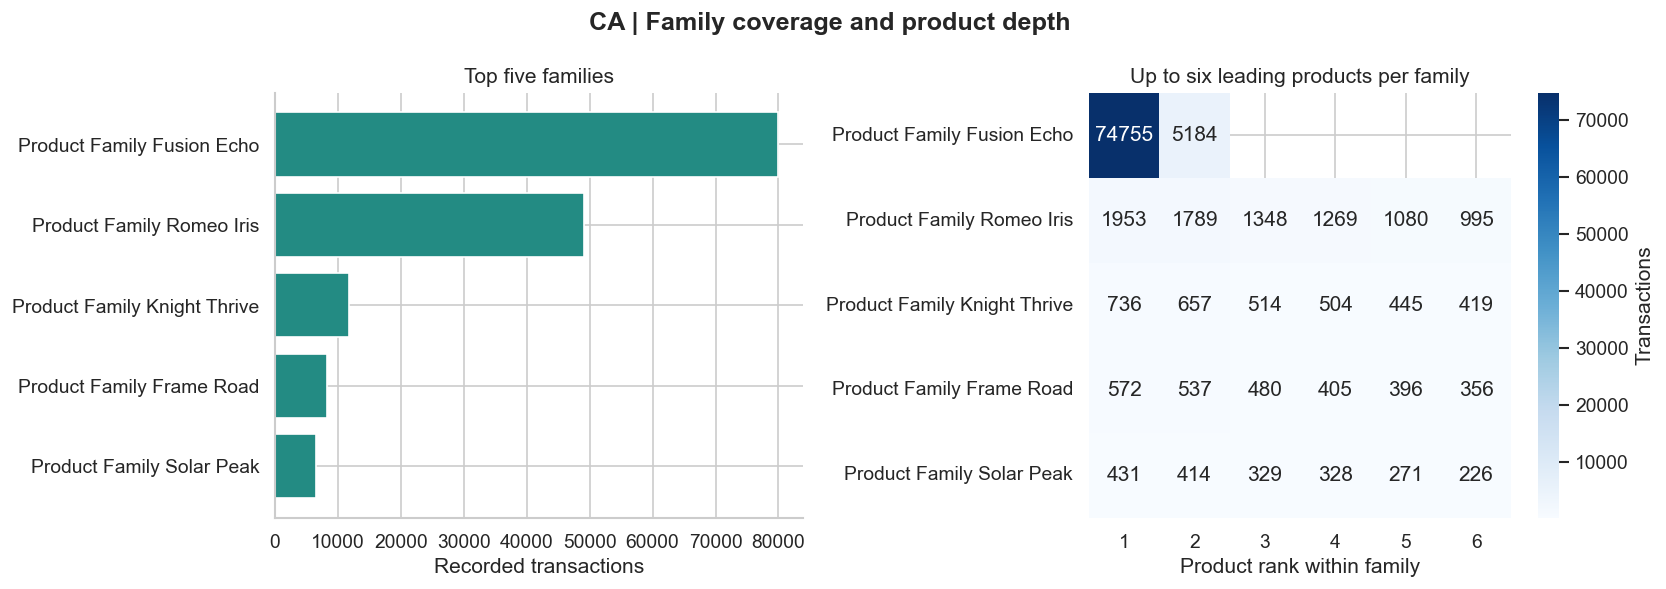

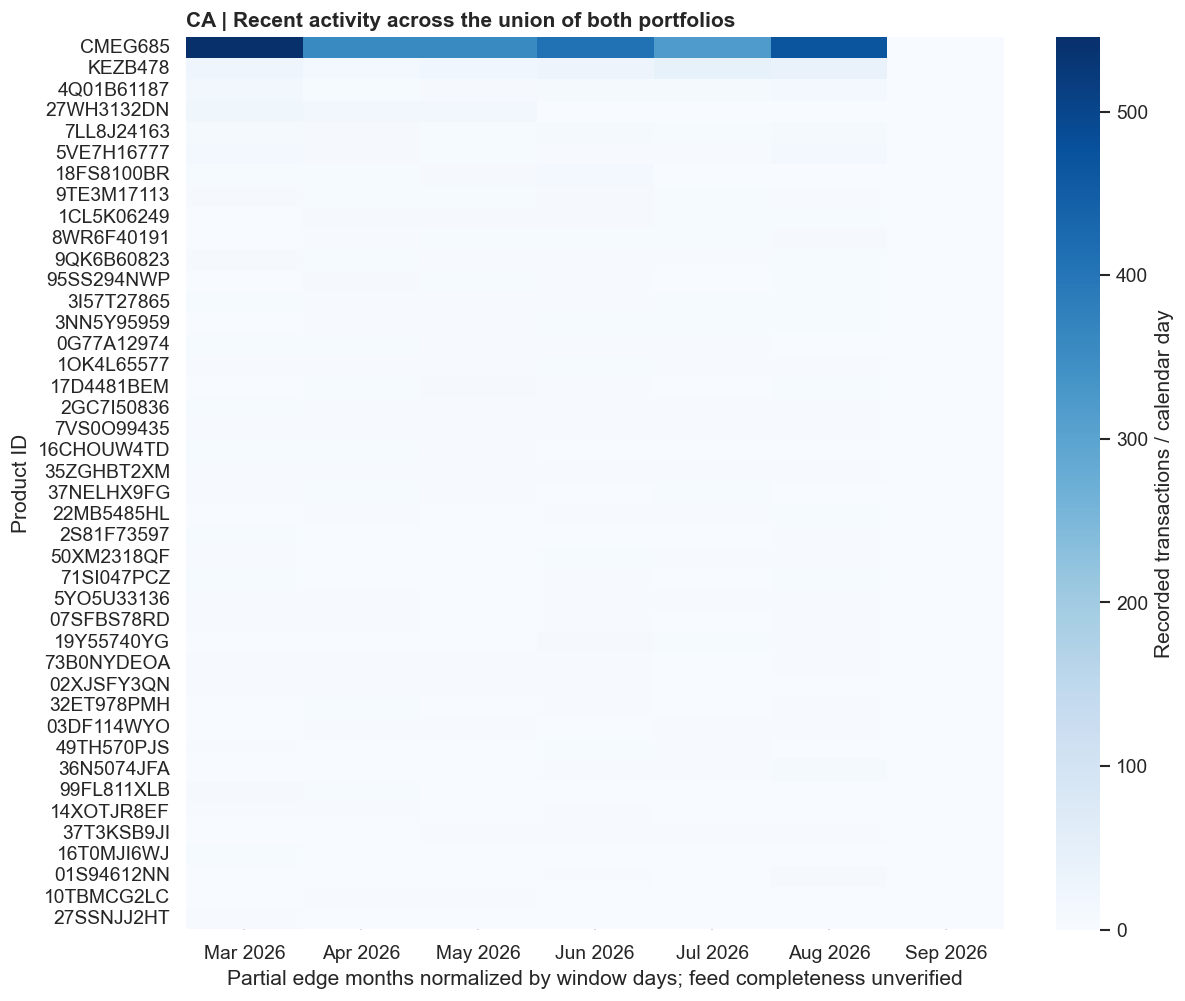

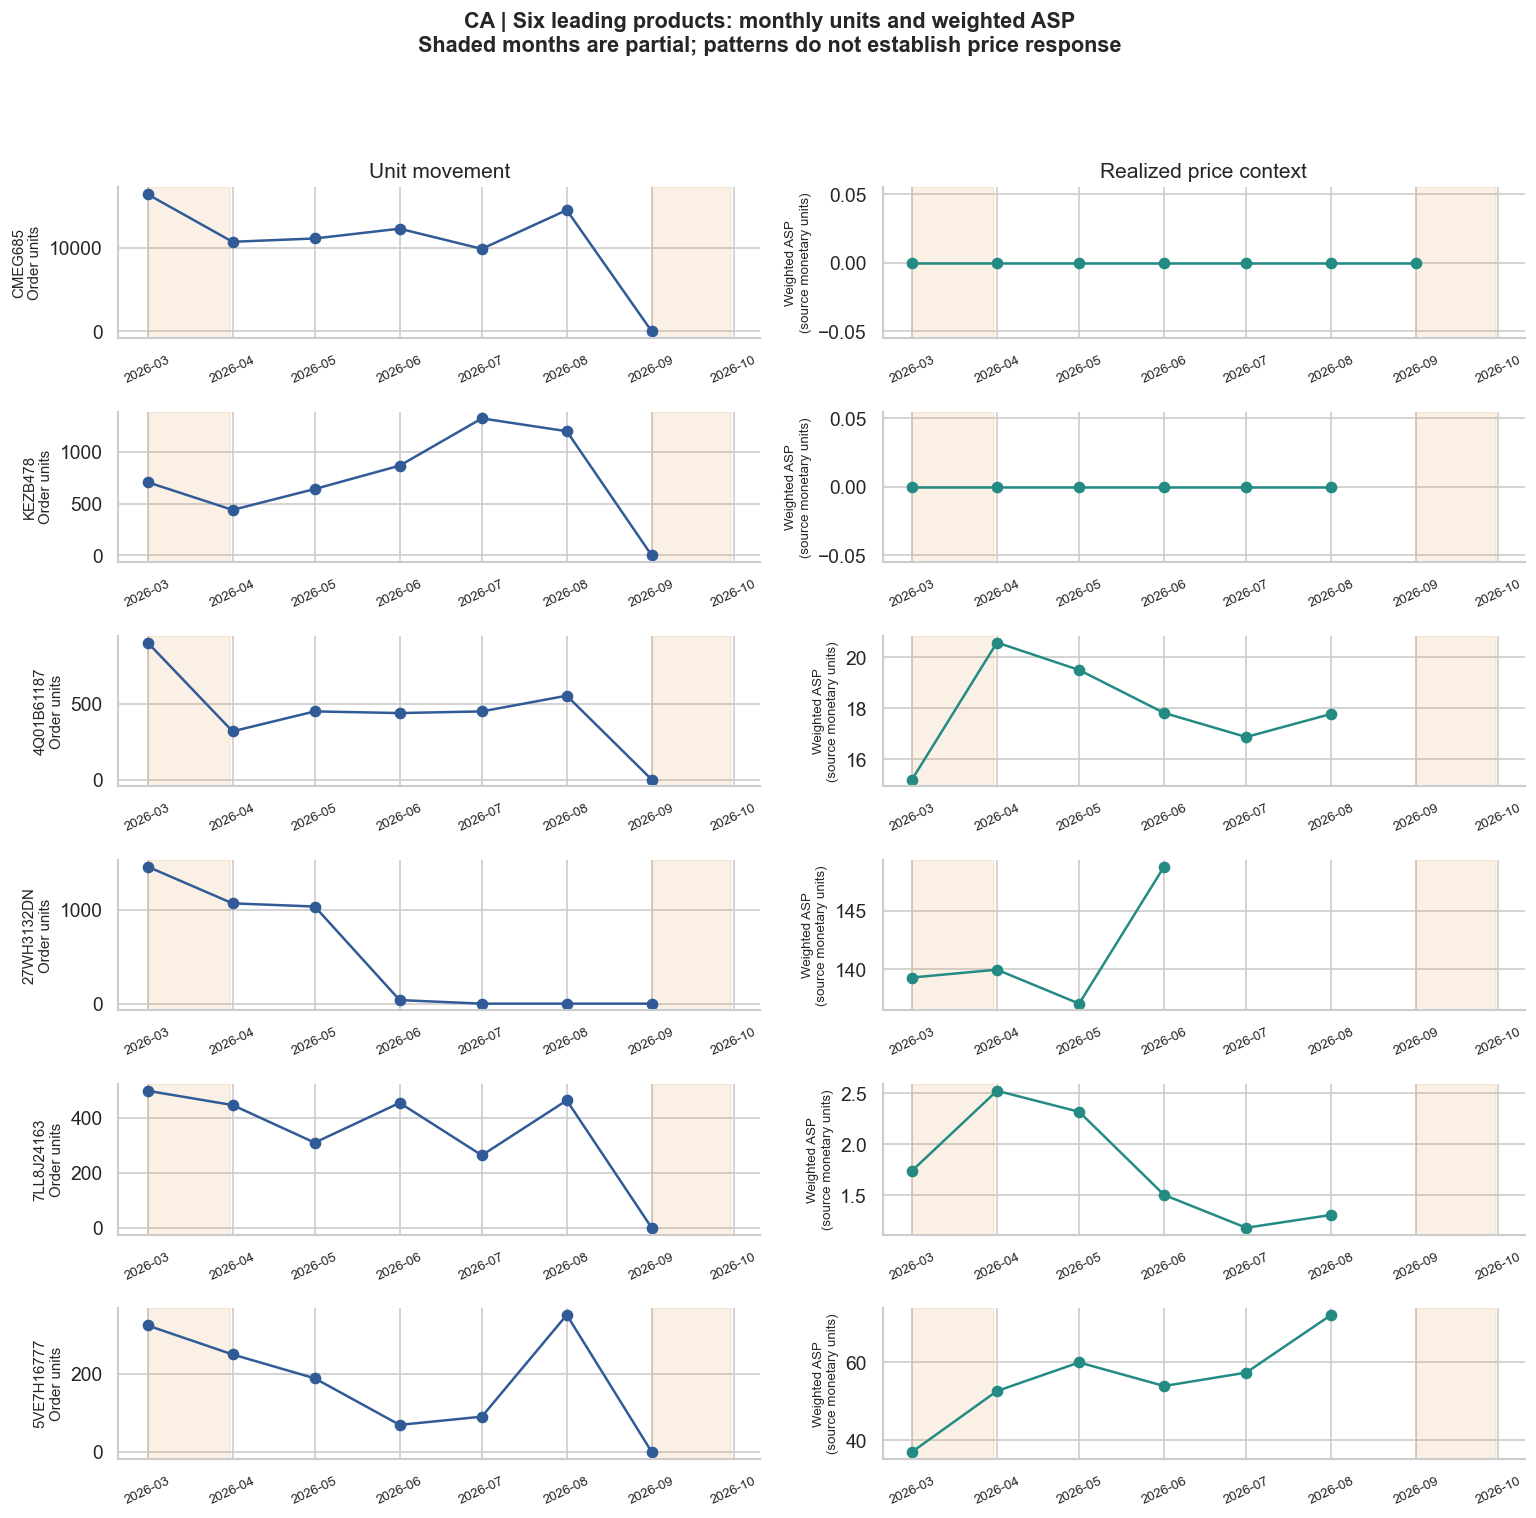

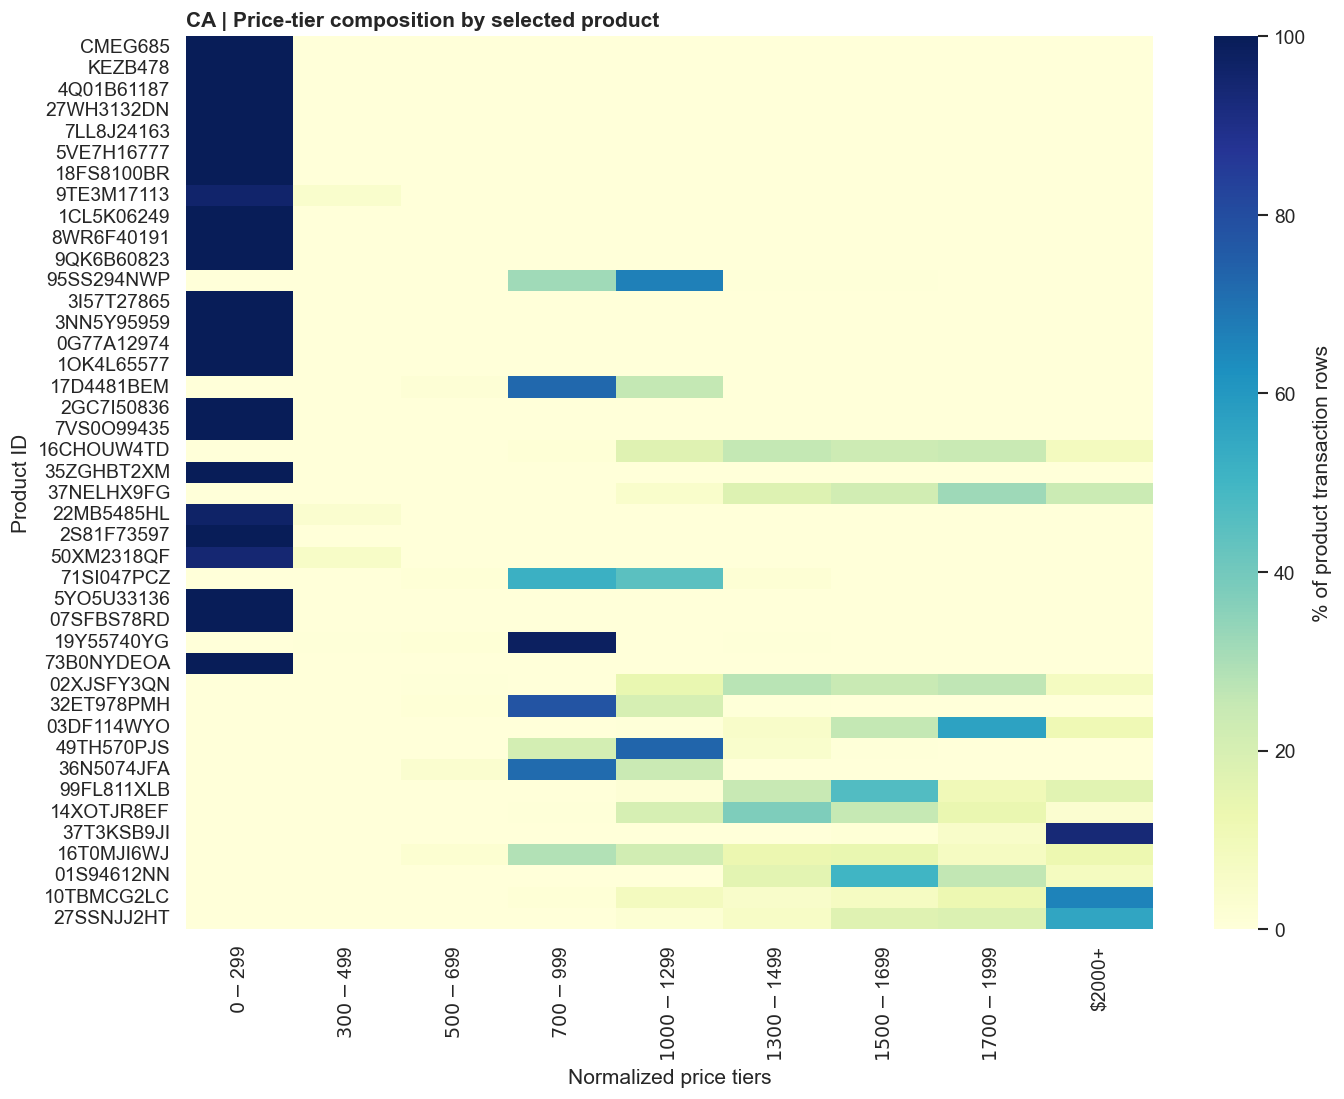

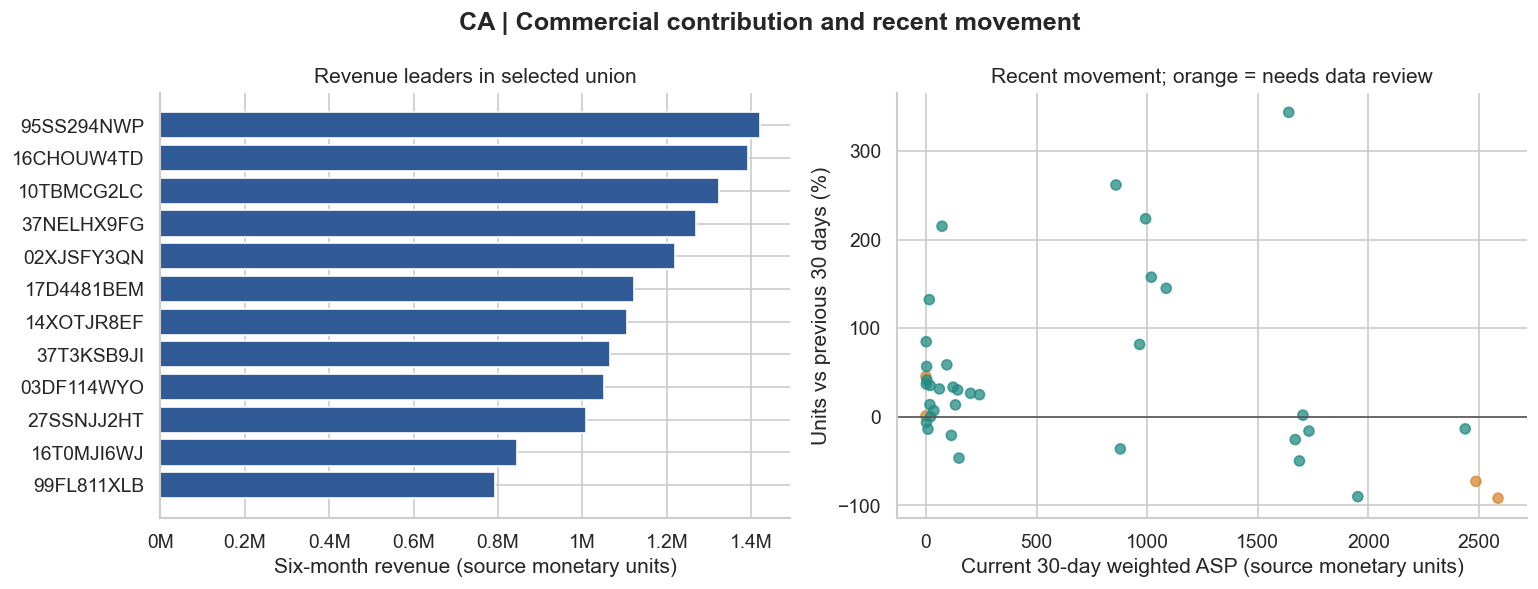

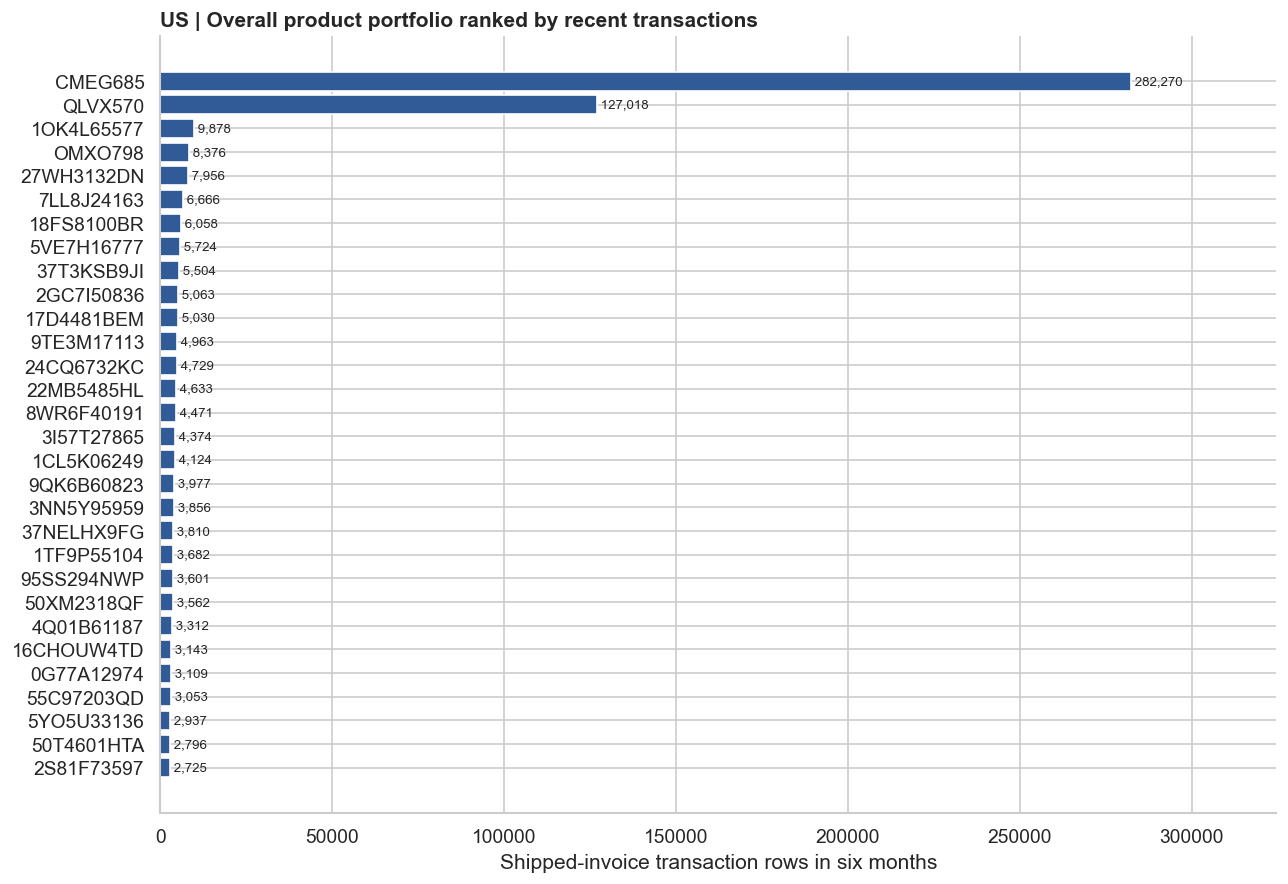

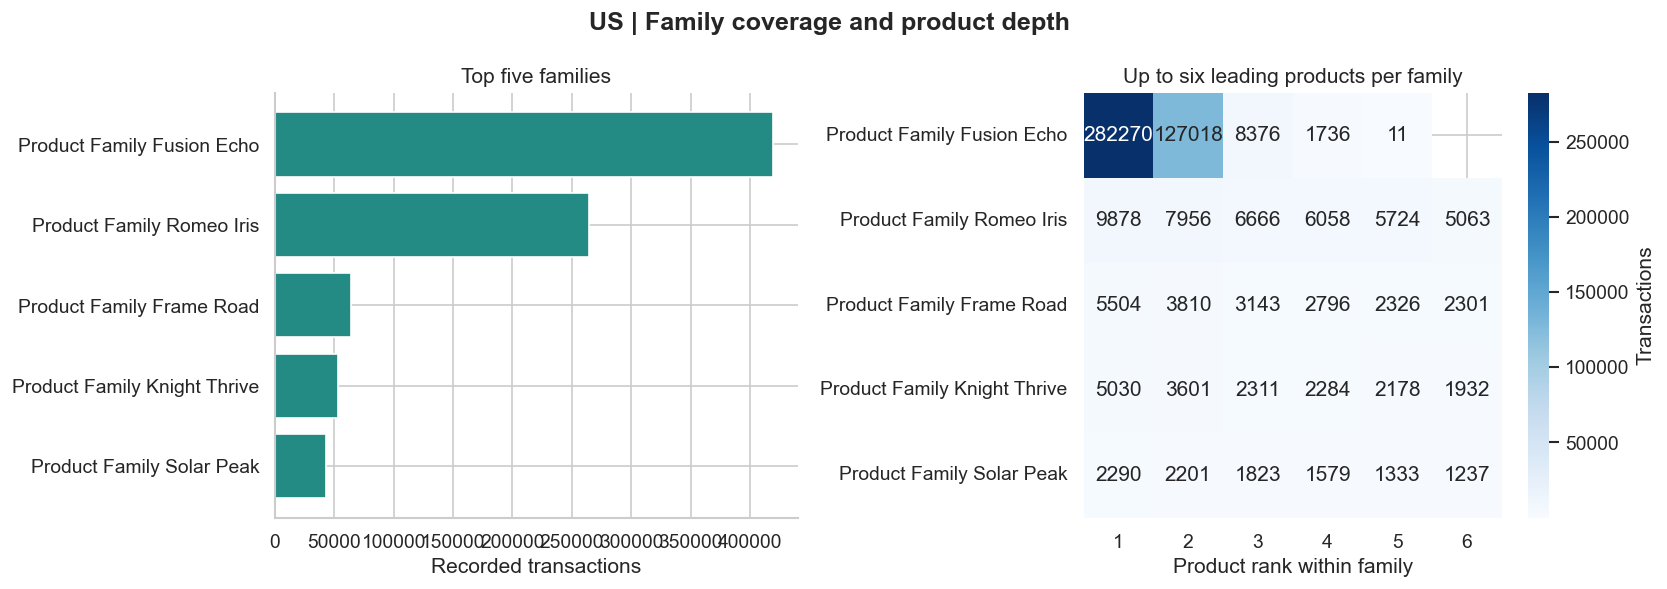

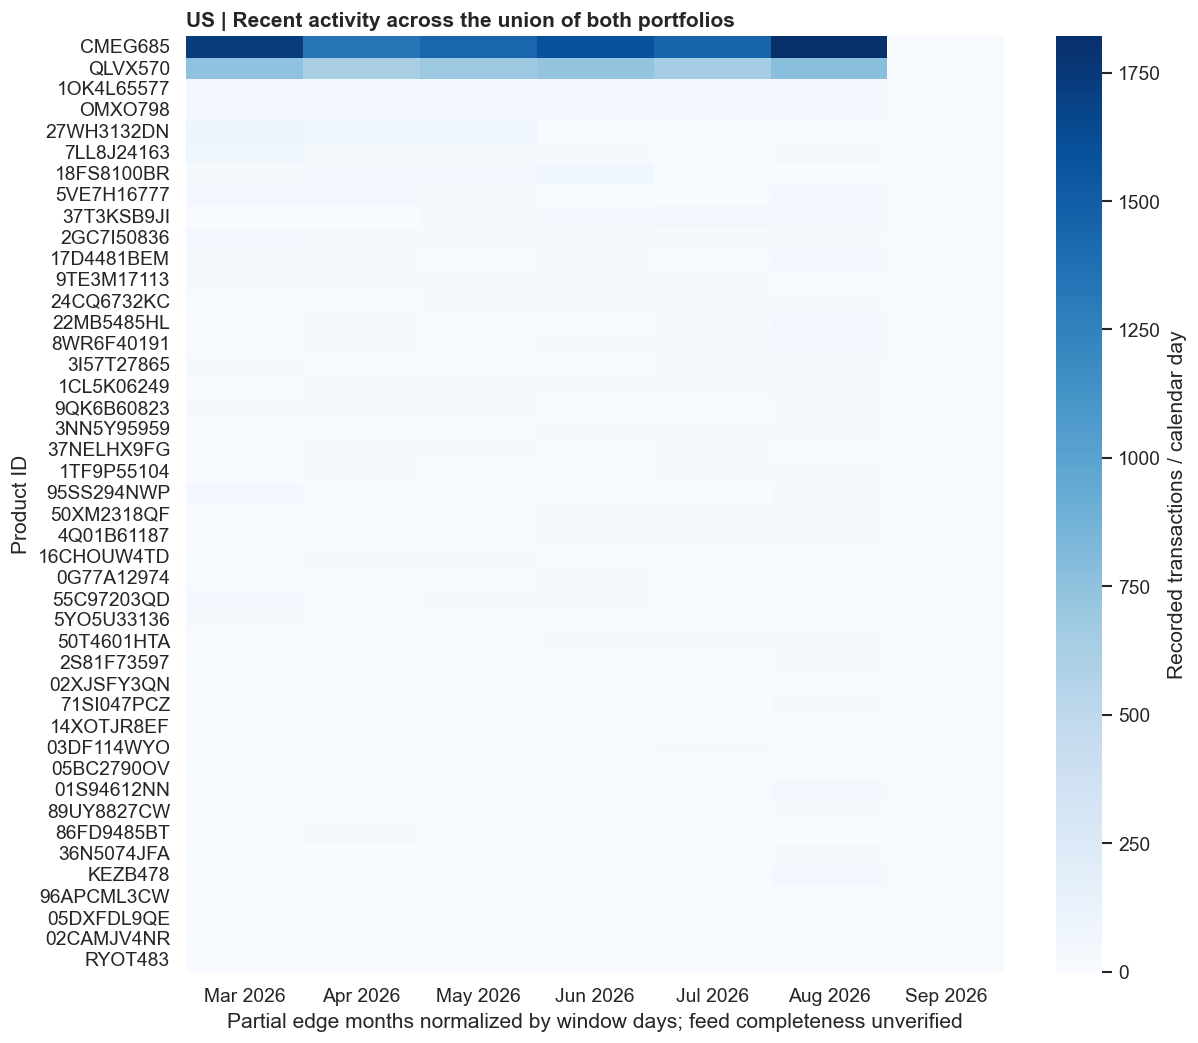

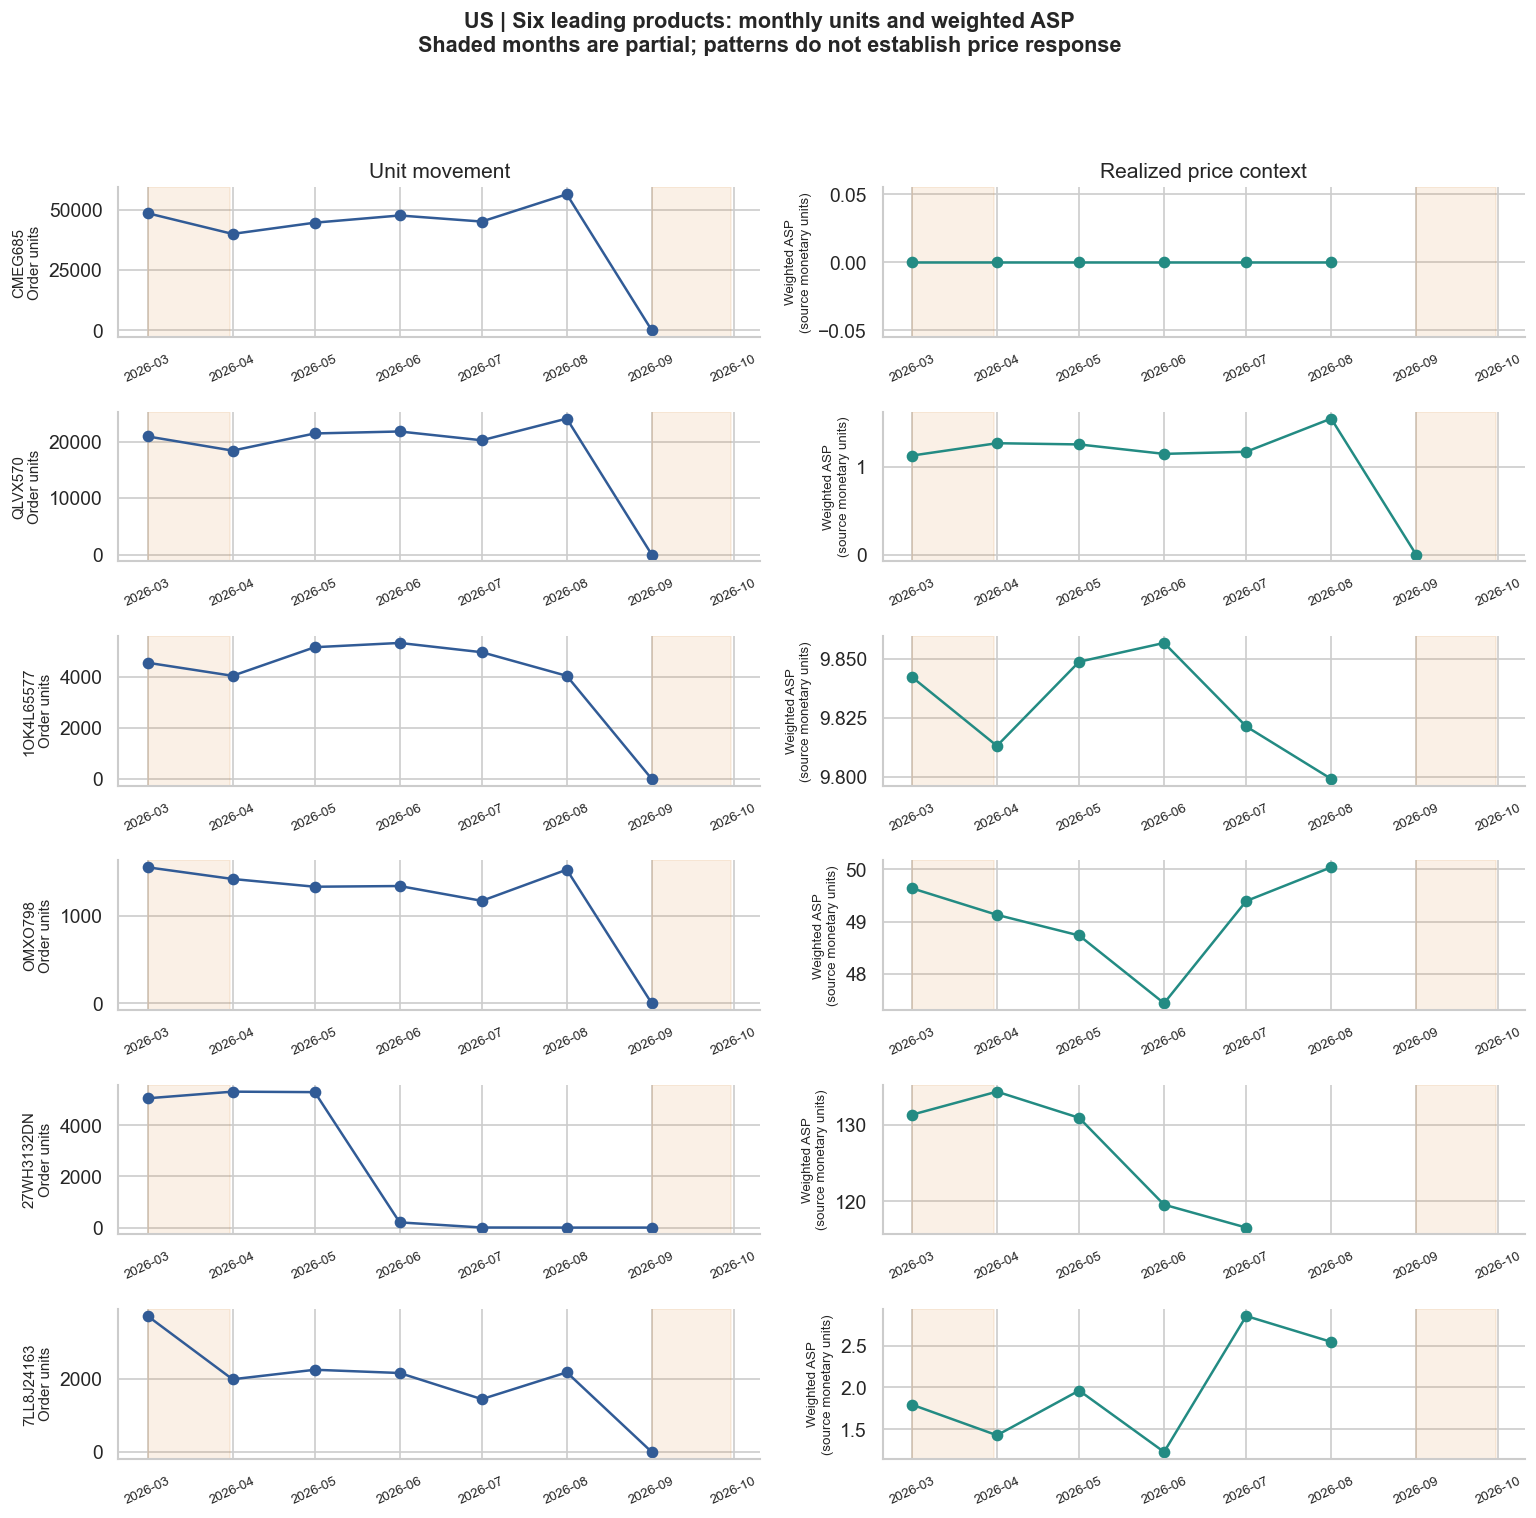

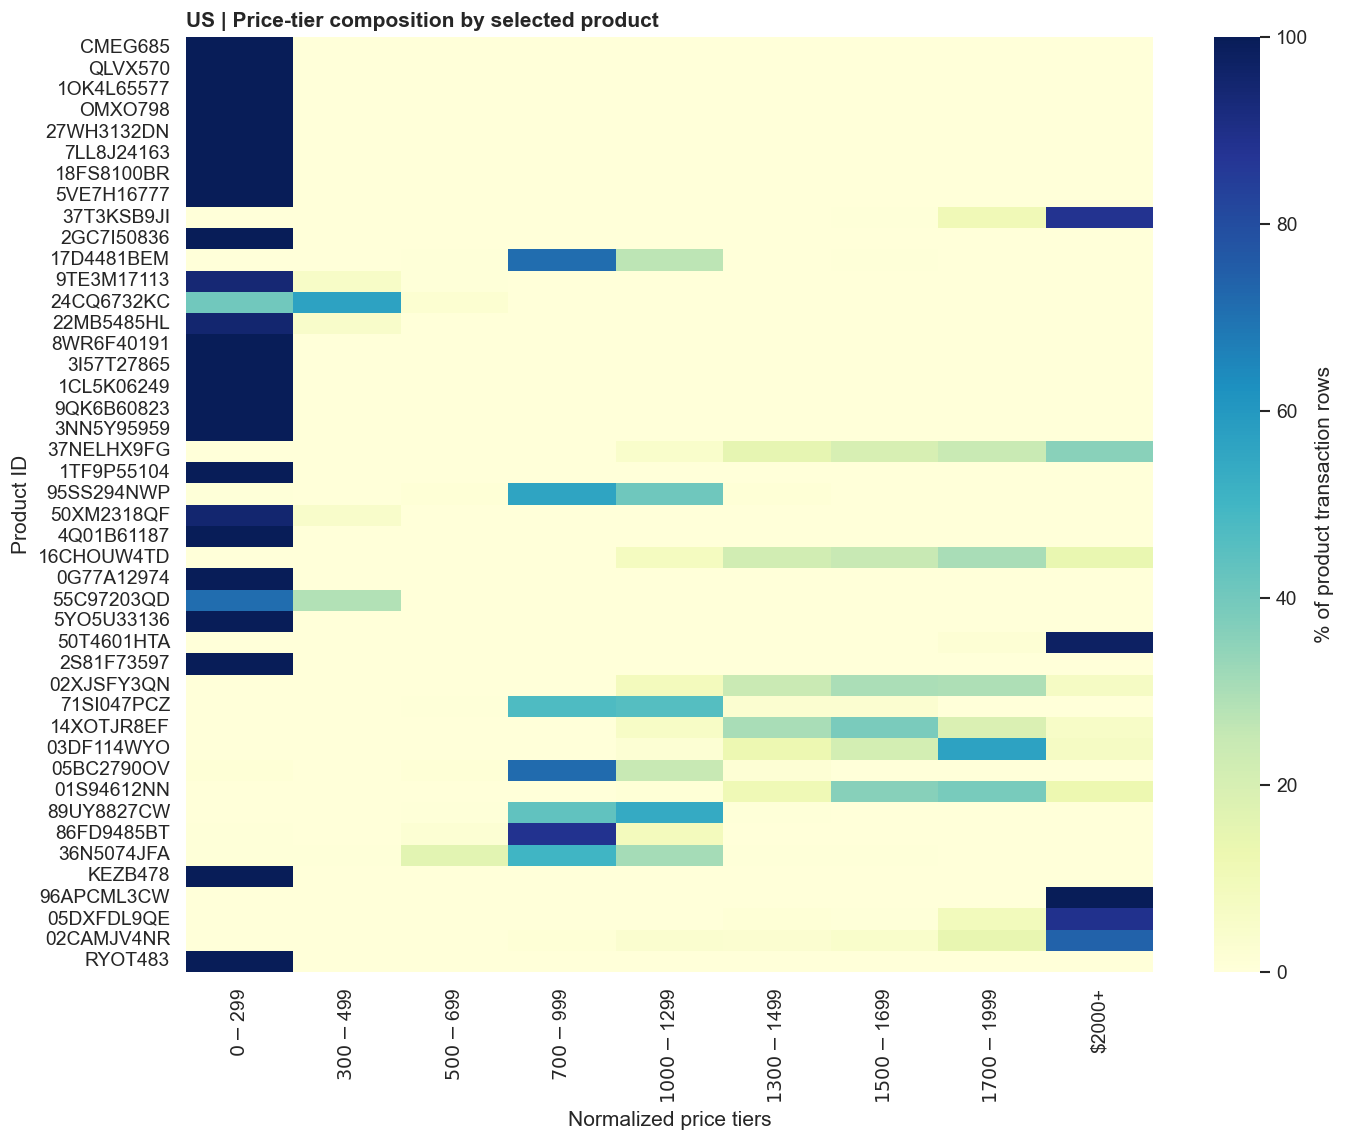

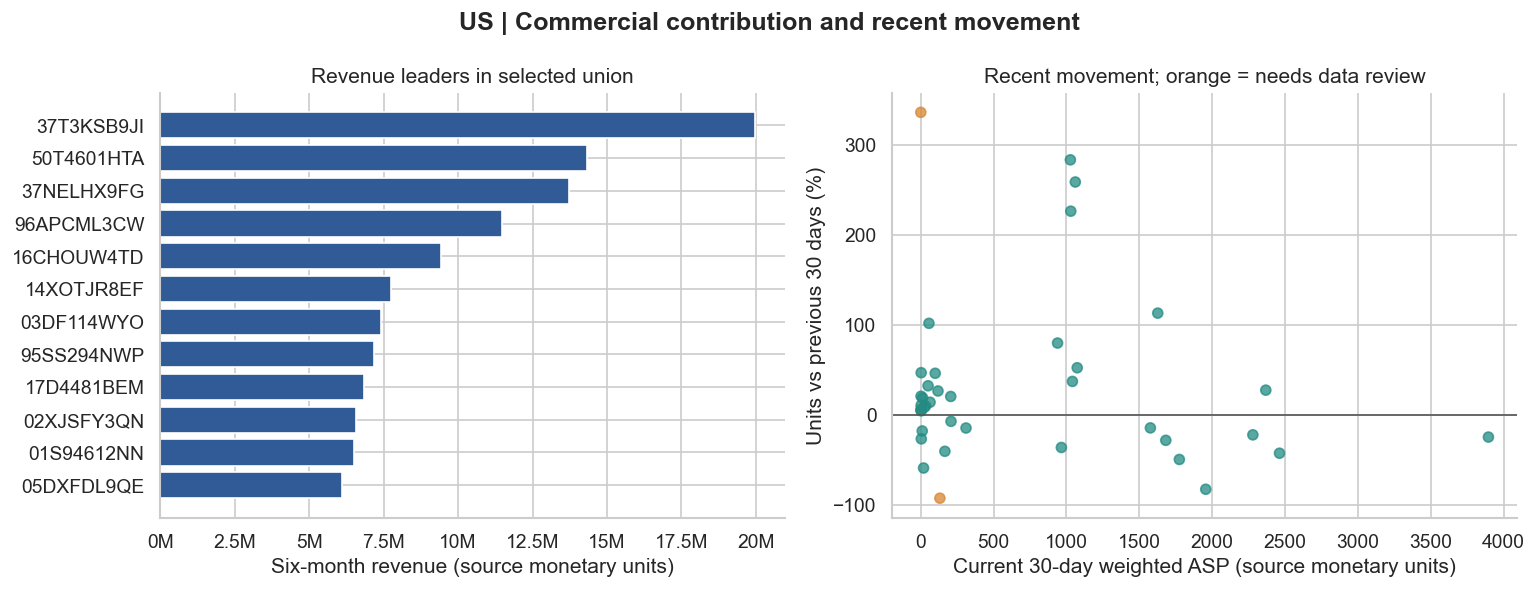

In [7]:
def finish(fig, path):
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show(); plt.close(fig)

def make_figures(c, a):
    out = OUTPUT_DIR / c; out.mkdir(exist_ok=True)
    top, fam, detail, mon = a["top"], a["families"], a["detail"], a["monthly"]
    fig, ax = plt.subplots(figsize=(12, max(6, len(top)*.28)))
    y = np.arange(len(top)); ax.barh(y, top.transactions, color=BLUE); ax.invert_yaxis()
    ax.set_yticks(y, top.product_id); ax.set_xlabel("Shipped-invoice transaction rows in six months")
    ax.set_title(f"{c} | Overall product portfolio ranked by recent transactions", loc="left", fontweight="bold")
    for pos,n in zip(y,top.transactions): ax.text(n,pos,f" {n:,.0f}",va="center",fontsize=8)
    ax.margins(x=.15); finish(fig,out/"01_top30_transactions.png")
    if not fam.empty:
        fig, axes = plt.subplots(1,2,figsize=(14,5))
        axes[0].barh(fam.product_family, fam.transactions,color=TEAL); axes[0].invert_yaxis()
        axes[0].set_xlabel("Recorded transactions"); axes[0].set_title("Top five families")
        fp = a["family_products"]
        mat = fp.pivot(index="product_family", columns="within_family_rank", values="transactions").reindex(fam.product_family)
        sns.heatmap(mat,annot=True,fmt=".0f",cmap="Blues",ax=axes[1],cbar_kws={"label":"Transactions"})
        axes[1].set_xlabel("Product rank within family"); axes[1].set_ylabel(""); axes[1].set_title("Up to six leading products per family")
        fig.suptitle(f"{c} | Family coverage and product depth",fontweight="bold"); fig.tight_layout(); finish(fig,out/"02_family_selection.png")
    heat = mon.pivot(index="product_id", columns="month", values="transactions_per_calendar_day").reindex(detail.product_id)
    heat.columns = [t.strftime("%b %Y") for t in heat.columns]
    fig,ax=plt.subplots(figsize=(11,max(6,len(heat)*.23)))
    sns.heatmap(heat,cmap="Blues",ax=ax,cbar_kws={"label":"Recorded transactions / calendar day"})
    ax.set_title(f"{c} | Recent activity across the union of both portfolios",loc="left",fontweight="bold")
    ax.set_xlabel("Partial edge months normalized by window days; feed completeness unverified"); ax.set_ylabel("Product ID")
    finish(fig,out/"03_transaction_frequency_heatmap.png")
    keys = top.product_id.head(6).tolist()
    fig, axes=plt.subplots(len(keys),2,figsize=(13,max(5,len(keys)*2.15)),squeeze=False)
    for i,pid in enumerate(keys):
        z=mon.loc[mon.product_id.eq(pid)].sort_values("month")
        axes[i,0].plot(z.month,z.units,marker="o",color=BLUE)
        axes[i,1].plot(z.month,z.asp,marker="o",color=TEAL)
        for j in range(2):
            for t in z.loc[z.partial_month,"month"]: axes[i,j].axvspan(t,t+pd.offsets.MonthEnd(0),color=ORANGE,alpha=.12)
            axes[i,j].tick_params(axis="x",rotation=25,labelsize=8)
        axes[i,0].set_ylabel(f"{pid}\nOrder units",fontsize=9); axes[i,1].set_ylabel("Weighted ASP\n(source monetary units)",fontsize=8)
    axes[0,0].set_title("Unit movement"); axes[0,1].set_title("Realized price context")
    fig.suptitle(f"{c} | Six leading products: monthly units and weighted ASP\nShaded months are partial; patterns do not establish price response",fontsize=13,fontweight="bold")
    fig.tight_layout(rect=[0,0,1,.94]); finish(fig,out/"04_product_patterns.png")
    tiers=a["tiers"].copy(); tiers["price_tier"]=tiers.price_tier.fillna("Unknown")
    mat=tiers.pivot(index="product_id",columns="price_tier",values="transaction_share_within_product").fillna(0).reindex(detail.product_id)
    tier_order=sorted(mat.columns,key=lambda t: (np.inf if pd.isna(tier_bounds(t)[0]) else tier_bounds(t)[0],str(t)))
    mat=mat[tier_order]
    fig,ax=plt.subplots(figsize=(13,max(6,len(mat)*.23)))
    sns.heatmap(mat*100,cmap="YlGnBu",vmin=0,vmax=100,ax=ax,cbar_kws={"label":"% of product transaction rows"})
    ax.set_title(f"{c} | Price-tier composition by selected product",loc="left",fontweight="bold")
    ax.set_xlabel("Normalized price tiers"); ax.set_ylabel("Product ID"); finish(fig,out/"05_price_tier_composition.png")
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    sample=detail.sort_values("revenue",ascending=False).head(12).iloc[::-1]
    axes[0].barh(sample.product_id,sample.revenue,color=BLUE); axes[0].set_xlabel("Six-month revenue (source monetary units)")
    axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f"{x/1e6:g}M")); axes[0].set_title("Revenue leaders in selected union")
    axes[1].scatter(detail.current30_asp,detail.unit_growth_30d*100,
                    c=np.where(detail.recent_review_ready,TEAL,ORANGE),alpha=.75)
    axes[1].axhline(0,color="#555",lw=1); axes[1].set_xlabel("Current 30-day weighted ASP (source monetary units)")
    axes[1].set_ylabel("Units vs previous 30 days (%)"); axes[1].set_title("Recent movement; orange = needs data review")
    fig.suptitle(f"{c} | Commercial contribution and recent movement",fontweight="bold")
    fig.tight_layout();finish(fig,out/"06_revenue_and_recent_movement.png")

if RUN_CHARTS:
    for country, analysis in analyses.items(): make_figures(country, analysis)

## 7. Export computed findings and review tables
Exports cover both portfolios, overlap, families, pricing flags, monthly metrics, and examples needing review. The findings text is built from actual loaded data and includes exact dates and limits. No new client-specific rankings are asserted before the CSVs are run.

Monthly/fiscal patterns are descriptive; the six-month selection cannot establish recurring seasonality. Historical FY files may contain transactions outside their named quarters. Pricing readiness flags must be reviewed alongside input completeness and accounting checks.

In [8]:
findings = ["# PriceWise: recent product and pricing findings", "",
            "Generated from the configured CSV input files. Scope: " + ", ".join(sorted(SEGMENTS)) + "; shipped invoice records.",
            "Transaction = input row; duplicates retained. Countries are analyzed separately; currency basis is not verified.", ""]
for c,a in analyses.items():
    out=OUTPUT_DIR/c; out.mkdir(exist_ok=True)
    for key,name in [("top","overall_top30"),("families","top5_families"),("family_products","top6_per_family"),
                     ("detail","selected_product_metrics"),("monthly","monthly_product_patterns"),("tiers","product_price_tiers"),
                     ("pricing_flags","pricing_quality_flags"),("returns","return_flow_metrics"),("outlier_examples","transactions_for_review"),("portfolio_coverage","portfolio_size_coverage"),("product_type_mix","selected_product_type_mix")]:
        a[key].to_csv(out/f"{name}.csv",index=False)
    top,fam,fp,member,detail=a["top"],a["families"],a["family_products"],a["membership"],a["detail"]
    overlap=int((member.in_overall_top30 & member.in_family_top6).sum())
    end=a["end"];start=end-pd.DateOffset(months=6)+pd.Timedelta(days=1)
    leader=top.iloc[0]
    positive_revenue_total=a["recent"][REVENUE_COL].sum(min_count=1)
    share=safe_div(top.revenue.sum(min_count=1),positive_revenue_total)
    findings += [f"## {c}: {start.date()} through {end.date()} (inclusive)",
      f"- Eligible six-month transaction rows: {len(a['recent']):,}; unique products: {len(a['products']):,}.",
      f"- Overall portfolio: {len(top)} products. Family portfolio: {len(fp)} products across {len(fam)} families. Overlap: {overlap}; union: {len(member)} products.",
      f"- Highest-transaction product: {leader.product_id} ({leader.product_name}), {int(leader.transactions):,} transactions; resolved family: {leader.product_family}.",
      f"- Overall portfolio share of recorded transactions: {top.transactions.sum()/len(a['recent']):.1%}; share of signed revenue: {share:.1%} (interpret negative credits carefully).",
      f"- Selected products passing provisional recent-data checks: {int(detail.recent_review_ready.sum())}/{len(detail)}. This is not operational price approval.",
      f"- Family slots unavailable: {int(fam.shortfall.sum())}; overall slots unavailable: {max(0,TOP_N-len(top))}.",
      f"- Selected products with conflicting family assignments: {int(detail.product_family_variants.gt(1).sum())}.",
      f"- Selected products with declining units versus the previous 30 days: {int(detail.unit_growth_30d.lt(0).sum())}; undefined growth comparison: {int(detail.unit_growth_30d.isna().sum())}.",
      f"- Products missing at least one illustrative baseline component: {int(detail.baseline_component_missing.sum())}. Do not silently substitute a family average.", "",
      "### Selected families", "", "| Family | Transactions | Selected products | Unfilled slots |", "|---|---:|---:|---:|"]
    for r in fam.itertuples(): findings.append(f"| {r.product_family} | {r.transactions:,} | {r.selected_products} | {r.shortfall} |")
    findings += ["", "### Product review priorities", ""]
    for r in detail.loc[~detail.recent_review_ready].head(12).itertuples(): findings.append(f"- {r.product_id}: {r.readiness_reason}.")
    findings += ["", "### Pricing interpretation", "",
      "- ASP is realized revenue / order units, not list price. Investigate signed credits, zero-priced shipping/services and bulk contracts before suggesting a price change.",
      "- Family price context mixes products; compare product type/tier and family-to-product ASP ratios before using the illustrative 50/30/20 baseline.",
      "- .99-ending incidence is observed transaction ASP only. It does not prove list-price endings or customer preference.",
      "- Orange-shaded trend months are partial. Calendar-day normalization does not validate daily feed completeness.",
      "- Declining recorded sales is not proven excess inventory. Returns are an unlinked same-window flow ratio, not a cohort return rate.", ""]
findings += ["## Next decisions", "",
  "Confirm revenue/cost/margin currency basis; confirm ship_date as invoice-event proxy and data completeness date; agree the family mapping and scope of non-hardware products; approve recent-data thresholds. Use fixed tier/margin rules and the documented ±2% daily and ±10% monthly limits only after reference prices and costs are validated.", "",
  "No causal demand response, optimized stakeholder weights, realized revenue uplift, or inventory reduction is estimated in this EDA. These require additional data and evaluation."]
findings_text="\n".join(findings)
(OUTPUT_DIR/"FINDINGS.md").write_text(findings_text,encoding="utf-8")
manifest={"input_files":[str(p) for p in files], "segments":sorted(SEGMENTS),"revenue_column":REVENUE_COL,
 "country_partitioned":True,"as_of_override":AS_OF,"top_n":TOP_N,"top_families":TOP_FAMILIES,"products_per_family":PRODUCTS_PER_FAMILY,
 "readiness":{"min_30d_transactions":MIN_30D_TRANSACTIONS,"min_30d_active_days":MIN_30D_ACTIVE_DAYS,"max_recency_days":MAX_RECENCY_DAYS}}
(OUTPUT_DIR/"run_configuration.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
display(Markdown(findings_text))
print("Exports written to",OUTPUT_DIR.resolve())

# PriceWise: recent product and pricing findings

Generated from the configured CSV input files. Scope: enterprise; shipped invoice records.
Transaction = input row; duplicates retained. Countries are analyzed separately; currency basis is not verified.

## CA: 2026-03-02 through 2026-09-01 (inclusive)
- Eligible six-month transaction rows: 164,802; unique products: 1,418.
- Overall portfolio: 30 products. Family portfolio: 26 products across 5 families. Overlap: 14; union: 42 products.
- Highest-transaction product: CMEG685 (LIBERTY INTEGRAL JUNCTION (FKA)), 74,755 transactions; resolved family: Product Family Fusion Echo.
- Overall portfolio share of recorded transactions: 61.9%; share of signed revenue: 11.1% (interpret negative credits carefully).
- Selected products passing provisional recent-data checks: 34/42. This is not operational price approval.
- Family slots unavailable: 4; overall slots unavailable: 0.
- Selected products with conflicting family assignments: 0.
- Selected products with declining units versus the previous 30 days: 15; undefined growth comparison: 1.
- Products missing at least one illustrative baseline component: 5. Do not silently substitute a family average.

### Selected families

| Family | Transactions | Selected products | Unfilled slots |
|---|---:|---:|---:|
| Product Family Fusion Echo | 79,939 | 2 | 4 |
| Product Family Romeo Iris | 49,028 | 6 | 0 |
| Product Family Knight Thrive | 11,803 | 6 | 0 |
| Product Family Frame Road | 8,269 | 6 | 0 |
| Product Family Solar Peak | 6,432 | 6 | 0 |

### Product review priorities

- CMEG685: invalid recent price basis.
- KEZB478: invalid recent price basis.
- 27WH3132DN: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- 49TH570PJS: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- 99FL811XLB: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- 16T0MJI6WJ: few recent transactions; few active sales days.
- 10TBMCG2LC: few recent transactions; few active sales days; stale sales.
- 27SSNJJ2HT: few recent transactions; few active sales days; stale sales; invalid recent price basis.

### Pricing interpretation

- ASP is realized revenue / order units, not list price. Investigate signed credits, zero-priced shipping/services and bulk contracts before suggesting a price change.
- Family price context mixes products; compare product type/tier and family-to-product ASP ratios before using the illustrative 50/30/20 baseline.
- .99-ending incidence is observed transaction ASP only. It does not prove list-price endings or customer preference.
- Orange-shaded trend months are partial. Calendar-day normalization does not validate daily feed completeness.
- Declining recorded sales is not proven excess inventory. Returns are an unlinked same-window flow ratio, not a cohort return rate.

## US: 2026-03-04 through 2026-09-03 (inclusive)
- Eligible six-month transaction rows: 892,300; unique products: 1,865.
- Overall portfolio: 30 products. Family portfolio: 29 products across 5 families. Overlap: 15; union: 44 products.
- Highest-transaction product: CMEG685 (LIBERTY INTEGRAL JUNCTION (FKA)), 282,270 transactions; resolved family: Product Family Fusion Echo.
- Overall portfolio share of recorded transactions: 60.6%; share of signed revenue: 14.0% (interpret negative credits carefully).
- Selected products passing provisional recent-data checks: 36/44. This is not operational price approval.
- Family slots unavailable: 1; overall slots unavailable: 0.
- Selected products with conflicting family assignments: 0.
- Selected products with declining units versus the previous 30 days: 19; undefined growth comparison: 1.
- Products missing at least one illustrative baseline component: 5. Do not silently substitute a family average.

### Selected families

| Family | Transactions | Selected products | Unfilled slots |
|---|---:|---:|---:|
| Product Family Fusion Echo | 419,411 | 5 | 1 |
| Product Family Romeo Iris | 264,252 | 6 | 0 |
| Product Family Frame Road | 63,566 | 6 | 0 |
| Product Family Knight Thrive | 53,257 | 6 | 0 |
| Product Family Solar Peak | 42,788 | 6 | 0 |

### Product review priorities

- CMEG685: invalid recent price basis.
- 27WH3132DN: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- 18FS8100BR: stale sales.
- 16CHOUW4TD: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- 55C97203QD: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- KEZB478: invalid recent price basis.
- 02CAMJV4NR: few recent transactions; few active sales days; stale sales; invalid recent price basis.
- RYOT483: few recent transactions; few active sales days; stale sales; invalid recent price basis.

### Pricing interpretation

- ASP is realized revenue / order units, not list price. Investigate signed credits, zero-priced shipping/services and bulk contracts before suggesting a price change.
- Family price context mixes products; compare product type/tier and family-to-product ASP ratios before using the illustrative 50/30/20 baseline.
- .99-ending incidence is observed transaction ASP only. It does not prove list-price endings or customer preference.
- Orange-shaded trend months are partial. Calendar-day normalization does not validate daily feed completeness.
- Declining recorded sales is not proven excess inventory. Returns are an unlinked same-window flow ratio, not a cohort return rate.

## Next decisions

Confirm revenue/cost/margin currency basis; confirm ship_date as invoice-event proxy and data completeness date; agree the family mapping and scope of non-hardware products; approve recent-data thresholds. Use fixed tier/margin rules and the documented ±2% daily and ±10% monthly limits only after reference prices and costs are validated.

No causal demand response, optimized stakeholder weights, realized revenue uplift, or inventory reduction is estimated in this EDA. These require additional data and evaluation.

Exports written to /Users/shambhavikhanna/Downloads/Capstone/pricewise_eda_results


## 8. What changed, and why
| Change | Why it matters for PriceWise |
|---|---|
| Two six-month portfolios, ranked by transaction count | Implements the team's specific selection criteria instead of all-time revenue leaders. |
| Enterprise shipped invoices only | Aligns KPI population with Stage 1; cancellations, orders and returns do not inflate primary sales. |
| Product ID as decision key; name as label | Avoids combining different IDs that share a name or splitting one ID with label variations. |
| Family mapping conflicts and shortfalls surfaced | Makes the five-family/six-product selection reproducible and reviewable. |
| Duplicate preservation and source-row IDs | Follows the client rule and retains an audit trail without claiming unique invoice transactions. |
| Ship-date windows and April-start fiscal calendar | Avoids deriving transaction periods from FY filenames that may disagree with actual dates. |
| Country-specific currency partitions and revenue-field audit | Avoids treating mixed local-currency amounts as comparable dollar prices. |
| Ratio-of-sums ASP/margin rate, plus missing/signed-value flags | Uses unit-weighted pricing and preserves important credits, bulk orders and data issues. |
| Rolling 30/90-day metrics and recent readiness flags | Responds to Bob's concern about new/stale products and long gaps in sales history. |
| Family price-context ratio and missing baseline components | Checks whether the proposed family-based baseline is comparable before treating it as a recommendation. |
| Normalized tiers, mismatch diagnostics and observed .99 patterns | Connects EDA directly to price-tier guardrails and the client's psychological-pricing feedback. |
| Partial-month labels, heatmap and six-product small multiples | Makes changes in activity and realized pricing legible without a 30-product legend. |
| Separate return flow analysis | Corrects the old record-based return percentage without claiming a linked cohort return probability. |
| Computed findings and CSV/PNG exports | Provides a repeatable evidence package the whole team can review and commit to GitHub. |

## How this EDA informs the recommendation system
| System input | EDA evidence | Decision supported |
|---|---|---|
| Initial portfolio | Top 30 by six-month transaction count; 20/25/30 coverage table | Choose a manageable portfolio without replacing the requested count criterion with a revenue criterion. |
| Product baseline | Current 30-day product ASP, current family 90-day ASP, previous product 90-day ASP | Test the scope's 0.5/0.3/0.2 formula; show missing components and family price mismatch rather than silently imputing. |
| Revenue objective | Product revenue contribution and recent revenue metrics | Identify commercially important products for stable reference pricing; revenue importance alone is not a positive price signal. |
| Margin objective | Rolling margin / revenue and margin-versus-revenue-minus-cost audit | Compare with a stakeholder-approved target only after confirming cost and currency definitions. |
| Unit movement | Current-minus-previous 30-day units and growth | Identify products needing review; demand declines alone cannot prove lowering price will restore volume. |
| Clearance objective | Weak movement and observed gaps | Supply a weak-sales proxy. True clearance requires inventory, stock age and end-of-life data. |
| Fiscal context | April-start fiscal quarters, monthly panels, partial-month flags | Investigate timing; six months is too short to validate repeatable annual seasonality. |
| Tier guardrails | Normalized tiers, per-product tier variants and realized ASP mismatches | Establish which product-tier mapping requires approval before clamping a proposed price. |
| Data sufficiency | Recent count, active days, last sale, observed gaps and family conflicts | Route sparse, stale and ambiguous products to manual review. |
| Psychological pricing | Observed .99 ASP incidence | Explore the client's suggestion; realized ASP does not prove the list price or optimal ending. |
| Explanations | Metrics, membership, quality flags and reasons exported by ID | Show stakeholders the evidence and limitations behind each future recommendation. |

**Implementation order after this EDA:** validate accounting definitions and data completeness; approve SKU/family mapping and thresholds; agree comparable reference prices; define and normalize directional objective signals; apply baseline plus transparent stakeholder weights; enforce tier/margin/monthly/daily constraints; optionally round to .99 and recheck every constraint; record accept/reject/edit decisions. Back-test stability, coverage and guardrail frequency without claiming demand/revenue uplift from historical price correlation.

The ±2% daily bound must refer to the previous day's suggested price, and the ±10% monthly bound must refer to the agreed monthly reference. If their feasible ranges conflict with tier or margin rules, return a review flag rather than forcing a price. Any .99 rounding must remain inside the intersection of all approved bounds.

## Boundaries before recommendation design
This is product/pricing EDA, not a validated price optimizer. The illustrative baseline is a diagnostic only. No family fallback, .99 rounding, or weight optimization is used to fabricate a recommended price. True daily/monthly price guardrails need approved current/reference prices, the previous day's suggested price, confirmed tier boundaries and a validated minimum margin floor. Product-family context should not substitute for an unsupported product recommendation.